<a href="https://colab.research.google.com/github/michellefengym-glitch/Market-Analysis/blob/main/Capstone_Market_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Retail Sales and Customer Purchase Analysis**

*   Prepared by: Feng Yuanmei
*   Dataset Used: Market Analysis

## **1. Data import**

In [33]:
# Importing the initial required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

purchase_url = "https://raw.githubusercontent.com/michellefengym-glitch/Market-Analysis/refs/heads/main/purchase.csv"
customer_url = "https://raw.githubusercontent.com/michellefengym-glitch/Market-Analysis/refs/heads/main/customer.csv"

purchases = pd.read_csv(purchase_url)
customers = pd.read_csv(customer_url)

print("Purchase Data:")
purchases.info()
display(purchases.head())

print("Customer Data:")
customers.info()
display(customers.head())

Purchase Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       50000 non-null  object 
 1   customer_id    50000 non-null  object 
 2   product_name   50000 non-null  object 
 3   description    50000 non-null  object 
 4   price          50000 non-null  float64
 5   discount       50000 non-null  float64
 6   tax            50000 non-null  float64
 7   order_date     50000 non-null  object 
 8   quantity       50000 non-null  int64  
 9   shipping_cost  50000 non-null  float64
 10  shipping_date  50000 non-null  object 
dtypes: float64(4), int64(1), object(6)
memory usage: 4.2+ MB


,order_id,customer_id,product_name,description,price,discount,tax,order_date,quantity,shipping_cost,shipping_date
0,ODSHP00001,CS00001,Furniture,Transform your space with this stylish and fun...,645.52,0.37,0.02,26-05-2020,9,8.91,29-05-2020
1,ODSHP00002,CS00002,Dress,Look and feel your best with this elegant dress.,28.90,0.05,0.02,29-12-2022,9,13.95,29-12-2022
2,ODSHP00003,CS00003,Furniture,Transform your space with this stylish and fun...,3536.49,0.21,0.04,06-03-2021,3,36.42,06-03-2021
3,ODSHP00004,CS00004,Shoes,Step out in style with these fashionable shoes.,97.80,0.11,0.08,11-03-2020,7,9.35,13-03-2020
4,ODSHP00005,CS00005,Rugs,Add warmth and texture to your floors with the...,1785.38,0.13,0.00,12-03-2022,7,8.55,15-03-2022


Customer Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  1001 non-null   object
 1   first_name   1001 non-null   object
 2   last_name    1001 non-null   object
 3   gender       1001 non-null   object
 4   age          1001 non-null   int64 
 5   country      1001 non-null   object
 6   income       1001 non-null   int64 
dtypes: int64(2), object(5)
memory usage: 54.9+ KB


,customer_id,first_name,last_name,gender,age,country,income
0,CS00001,Isadora,Porto,Female,19,Brazil,117196
1,CS00002,Hugo,Carreño,Male,33,Chile,49256
2,CS00003,René,Olivera,Male,65,Mexico,33434
3,CS00004,Luiz Henrique,Pinto,Male,55,Brazil,75302
4,CS00005,Leonardo,Monteiro,Male,19,Brazil,32280


## **2. Data Cleansing & Preparation**

This section checks data quality, corrects data types and prepares
the customer and purchase datasets for analysis.




### **2.1 Missing Values and Duplicate Checks**

Check both datasets for missing values, duplicate rows and duplicate
identifiers to determine whether any records require further investigation.

In [34]:
# Missing Values and Duplicate Checks
print("Purchase missing values:")
display(purchases.isna().sum())

print("Customer missing values:")
display(customers.isna().sum())

# Duplicate rows
print("Duplicate purchase rows:", purchases.duplicated().sum())
print("Duplicate customer rows:", customers.duplicated().sum())

# Duplicate ID
print("Duplicate order IDs:", purchases["order_id"].duplicated().sum())
print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())

Purchase missing values:


,0
order_id,0
customer_id,0
product_name,0
description,0
price,0
discount,0
tax,0
order_date,0
quantity,0
shipping_cost,0


Customer missing values:


,0
customer_id,0
first_name,0
last_name,0
gender,0
age,0
country,0
income,0


Duplicate purchase rows: 0
Duplicate customer rows: 0
Duplicate order IDs: 0
Duplicate customer IDs: 0


 **Observations**

---



- No missing values or duplicate rows were found in either dataset.
- Order IDs in the purchase table and customer IDs in the customer
  table are unique.
- No missing-value imputation or duplicate removal is required
  at this stage.

### **2.2 Date Conversion and Validation**
Convert order and shipping dates to datetime format, check for
invalid dates and calculate the number of days between ordering
and shipping.

In [35]:
purchases_clean = purchases.copy()
customers_clean = customers.copy()

# Convert date columns
for column in ["order_date", "shipping_date"]:
    purchases_clean[column] = pd.to_datetime(
        purchases_clean[column],
        format="%d-%m-%Y",
        errors="coerce"
    )

# Check date conversion results
print("Missing or invalid dates:")
display(
    purchases_clean[["order_date", "shipping_date"]].isna().sum()
)

print("Earliest order:", purchases_clean["order_date"].min())
print("Latest order:", purchases_clean["order_date"].max())

# Calculate days from order placement to shipping
purchases_clean["days_to_ship"] = (
    purchases_clean["shipping_date"]
    - purchases_clean["order_date"]
).dt.days

print("Negative shipping durations:",
      (purchases_clean["days_to_ship"] < 0).sum())

display(purchases_clean["days_to_ship"].describe())

Missing or invalid dates:


,0
order_date,0
shipping_date,0


Earliest order: 2019-08-15 00:00:00
Latest order: 2023-01-01 00:00:00
Negative shipping durations: 0


,days_to_ship
count,50000.000000
mean,7.488680
std,4.610004
min,0.000000
25%,4.000000
50%,7.000000
75%,11.000000
max,15.000000


 **Observations**

---



- Both date columns were converted to datetime format, with no
  missing or invalid dates found after conversion.
- Order dates range from 15 August 2019 to 1 January 2023.
- No shipping dates occur before their corresponding order dates.
- The average time between ordering and shipping is approximately
  7.49 days.
- The first and last years contain partial periods, so annual sales
  comparisons should use complete years or equivalent date ranges.

### **2.3 Numerical Range and Validity Checks**

Examine numerical summaries and check for invalid prices, quantities,
discounts, tax rates, shipping costs, ages and incomes. Flag potential
issues for investigation before making any changes.

In [36]:
# Review numerical distributions
print("Purchase numerical summary:")
display(
    purchases_clean.select_dtypes(include="number")
    .describe().round(2)
)

print("Customer numerical summary:")
display(customers_clean.describe().round(2))

# Check basic validity rules
validity_checks = pd.Series({
    "Price <= 0":
        (purchases_clean["price"] <= 0).sum(),

    "Quantity <= 0":
        (purchases_clean["quantity"] <= 0).sum(),

    "Non-integer quantity":
        (purchases_clean["quantity"] % 1 != 0).sum(),

    "Discount outside 0–1":
        (~purchases_clean["discount"].between(0, 1)).sum(),

    "Tax outside 0–1":
        (~purchases_clean["tax"].between(0, 1)).sum(),

    "Shipping cost < 0":
        (purchases_clean["shipping_cost"] < 0).sum(),

    "Age <= 0":
        (customers_clean["age"] <= 0).sum(),

    "Non-integer age":
        (customers_clean["age"] % 1 != 0).sum(),

    "Income < 0":
        (customers_clean["income"] < 0).sum()
}, name="Flagged Records")

display(validity_checks.to_frame())

Purchase numerical summary:


,price,discount,tax,quantity,shipping_cost,days_to_ship
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,1275.93,0.25,0.05,5.50,27.51,7.49
std,1315.40,0.14,0.03,2.86,12.95,4.61
min,20.02,0.00,0.00,1.00,5.00,0.00
25%,219.68,0.12,0.03,3.00,16.36,4.00
50%,834.40,0.25,0.05,5.00,27.58,7.00
75%,1837.40,0.37,0.08,8.00,38.67,11.00
max,4999.95,0.50,0.10,10.00,50.00,15.00


Customer numerical summary:


,age,income
count,1001.00,1001.00
mean,41.34,84628.81
std,13.73,37498.01
min,18.00,20205.00
25%,29.00,52092.00
50%,41.00,83654.00
75%,53.00,116549.00
max,65.00,149980.00


,Flagged Records
Price <= 0,0
Quantity <= 0,0
Non-integer quantity,0
Discount outside 0–1,0
Tax outside 0–1,0
Shipping cost < 0,0
Age <= 0,0
Non-integer age,0
Income < 0,0


**Observations**

---



- No records violated the basic numerical validity rules.
- Prices range from 20.02 to 4,999.95, and quantities range
  from 1 to 10 units.
- Discount values range from 0 to 0.50, while tax values
  range from 0 to 0.10.
- Customer ages range from 18 to 65, and income values
  range from 20,205 to 149,980.
- No corrections are required based on the above checks.
  

### **2.4 Customer Matching and Data Integration**

Check whether all purchase records match an existing customer,
identify customers without recorded purchases, and combine the
two datasets using customer_id. Verify that the merge preserves
the number of purchase records.

In [37]:
# Find purchases with no matching customer
unmatched_purchases = purchases_clean.loc[
    ~purchases_clean["customer_id"].isin(
        customers_clean["customer_id"]
    )
]

print("Purchases without a matching customer:",
      len(unmatched_purchases))

# Find customers with no recorded purchases
customers_without_purchases = customers_clean.loc[
    ~customers_clean["customer_id"].isin(
        purchases_clean["customer_id"]
    )
]

print("Customers without recorded purchases:",
      len(customers_without_purchases))

display(customers_without_purchases[["customer_id"]])

# Merge customer information into purchase records
retail_data = purchases_clean.merge(
    customers_clean,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Verify the merge
print("\nPurchase rows before merge:", len(purchases_clean))
print("Rows after merge:", len(retail_data))

print("\nCustomer matching results:")
display(retail_data["_merge"].value_counts())

# Stop if the merge changes the number of purchase records
assert len(retail_data) == len(purchases_clean), \
    "The merge changed the number of purchase records."

# Remove the temporary matching indicator
retail_data = retail_data.drop(columns="_merge")

display(retail_data.head())

Purchases without a matching customer: 0
Customers without recorded purchases: 1


,customer_id
1000,CS01001



Purchase rows before merge: 50000
Rows after merge: 50000

Customer matching results:


,count
_merge,
both,50000
left_only,0
right_only,0


,order_id,customer_id,product_name,description,price,discount,tax,order_date,quantity,shipping_cost,shipping_date,days_to_ship,first_name,last_name,gender,age,country,income
0,ODSHP00001,CS00001,Furniture,Transform your space with this stylish and fun...,645.52,0.37,0.02,2020-05-26,9,8.91,2020-05-29,3,Isadora,Porto,Female,19,Brazil,117196
1,ODSHP00002,CS00002,Dress,Look and feel your best with this elegant dress.,28.90,0.05,0.02,2022-12-29,9,13.95,2022-12-29,0,Hugo,Carreño,Male,33,Chile,49256
2,ODSHP00003,CS00003,Furniture,Transform your space with this stylish and fun...,3536.49,0.21,0.04,2021-03-06,3,36.42,2021-03-06,0,René,Olivera,Male,65,Mexico,33434
3,ODSHP00004,CS00004,Shoes,Step out in style with these fashionable shoes.,97.80,0.11,0.08,2020-03-11,7,9.35,2020-03-13,2,Luiz Henrique,Pinto,Male,55,Brazil,75302
4,ODSHP00005,CS00005,Rugs,Add warmth and texture to your floors with the...,1785.38,0.13,0.00,2022-03-12,7,8.55,2022-03-15,3,Leonardo,Monteiro,Male,19,Brazil,32280


**Observations**

---



- All 50,000 purchase records successfully matched an existing
  customer.
- One customer (CS01001) has no recorded purchases and remains
  in the customer master table.
- The merged dataset contains 50,000 rows, confirming that the
  merge did not increase or reduce the number of purchase records.
- The integrated dataset combines transaction details with customer
  demographics for further analysis.


### **2.5 Sales Metric Definitions**
**Metric Definitions**

- Discounted Price = Price × (1 − Discount)
- Sales Before Tax = Discounted Price × Quantity
- Tax Amount = Sales Before Tax × Tax Rate
- Sales After Tax = Sales Before Tax + Tax Amount
- Order Total = Sales After Tax + Shipping Charge
- Average Order Value = Total Sales Before Tax ÷ Number of Unique Orders

Sales Before Tax is the main sales revenue measure used in this
project and excludes tax and shipping.

Order Total represents the calculated amount payable, not actual
collections. Shipping cost is assumed to be charged to the customer
without additional shipping tax.



In [38]:
# 1. Discounted Price: unit price after discount, before tax
retail_data["discounted_price"] = (
    retail_data["price"] * (1 - retail_data["discount"])
)

# 2. Sales Before Tax: excluding shipping
retail_data["sales_before_tax"] = (
    retail_data["discounted_price"] * retail_data["quantity"]
)

# 3. Tax Amount
retail_data["tax_amount"] = (
    retail_data["sales_before_tax"] * retail_data["tax"]
)

# 4. Sales After Tax: excluding shipping
retail_data["sales_after_tax"] = (
    retail_data["sales_before_tax"] + retail_data["tax_amount"]
)

# 5. Order Total: including tax and shipping once per order
retail_data["order_total"] = (
    retail_data["sales_after_tax"] + retail_data["shipping_cost"]
)

# 6. Average Order Value: before tax, excluding shipping
total_orders = retail_data["order_id"].nunique()
total_sales_before_tax = retail_data["sales_before_tax"].sum()
average_order_value = total_sales_before_tax / total_orders

# Preview the calculations
display(
    retail_data[[
        "order_id",
        "price",
        "discount",
        "discounted_price",
        "quantity",
        "sales_before_tax",
        "tax",
        "tax_amount",
        "sales_after_tax",
        "shipping_cost",
        "order_total"
    ]].head().round(2)
)

# Check calculated fields
calculated_columns = [
    "discounted_price",
    "sales_before_tax",
    "tax_amount",
    "sales_after_tax",
    "order_total"
]

print("Missing calculated values:")
display(retail_data[calculated_columns].isna().sum())

print("Negative calculated values:")
display(retail_data[calculated_columns].lt(0).sum())

# Display overall metrics without assuming a currency
print(f"\nTotal orders: {total_orders:,}")
print(f"Total sales before tax: {total_sales_before_tax:,.2f}")
print(f"Total tax: {retail_data['tax_amount'].sum():,.2f}")
print(f"Total sales after tax: {retail_data['sales_after_tax'].sum():,.2f}")
print(f"Total shipping charges: {retail_data['shipping_cost'].sum():,.2f}")
print(f"Total order amount payable: {retail_data['order_total'].sum():,.2f}")
print(f"Average order value before tax: {average_order_value:,.2f}")

,order_id,price,discount,discounted_price,quantity,sales_before_tax,tax,tax_amount,sales_after_tax,shipping_cost,order_total
0,ODSHP00001,645.52,0.37,406.68,9,3660.10,0.02,73.20,3733.30,8.91,3742.21
1,ODSHP00002,28.90,0.05,27.46,9,247.09,0.02,4.94,252.04,13.95,265.99
2,ODSHP00003,3536.49,0.21,2793.83,3,8381.48,0.04,335.26,8716.74,36.42,8753.16
3,ODSHP00004,97.80,0.11,87.04,7,609.29,0.08,48.74,658.04,9.35,667.39
4,ODSHP00005,1785.38,0.13,1553.28,7,10872.96,0.00,0.00,10872.96,8.55,10881.51


Missing calculated values:


,0
discounted_price,0
sales_before_tax,0
tax_amount,0
sales_after_tax,0
order_total,0


Negative calculated values:


,0
discounted_price,0
sales_before_tax,0
tax_amount,0
sales_after_tax,0
order_total,0



Total orders: 50,000
Total sales before tax: 263,688,338.84
Total tax: 13,266,431.83
Total sales after tax: 276,954,770.67
Total shipping charges: 1,375,464.06
Total order amount payable: 278,330,234.73
Average order value before tax: 5,273.77


**Observations**

---



- Sales metrics were calculated for all 50,000 orders.
- No missing or negative values were found in the calculated fields.
- Total sales before tax are 263,688,338.84, with an average
  order value of 5,273.77, excluding tax and shipping.
- Total tax is 13,266,431.83, and total shipping charges
  are 1,375,464.06.
- The calculated total amount payable is 278,330,234.73.
  This does not represent actual cash collected.


### **2.6 Feature Engineering**

Create year, month, year-month and quarter fields for time-based
analysis. Group customers into age bands and income ranges to
support demographic comparisons.

Age groups are 18–25, 26–35, 36–45, 46–55 and 56+.
Income is grouped into five ranges: below 30,000;
30,000 to below 60,000; 60,000 to below 90,000;
90,000 to below 120,000; and 120,000 or above.

Customer groups are created in both the customer table and the
merged transaction table. Customer distributions use the customer
table, while purchasing customer counts use unique customer IDs
in the transaction table to avoid repeated counting.

Products are grouped into three project-defined categories based
on their general use: Home & Living, Electronics, and Fashion & Apparel.
Original product names are retained for detailed analysis.

In [39]:
# Create time-based features
retail_data["order_year"] = retail_data["order_date"].dt.year
retail_data["order_month"] = retail_data["order_date"].dt.month

# Use YYYY-MM so months from different years remain separate
retail_data["order_yearmonth"] = (
    retail_data["order_date"].dt.strftime("%Y-%m")
)

retail_data["order_quarter"] = (
    retail_data["order_date"].dt.quarter
)

# Define age groups: upper boundary included
age_bins = [17, 25, 35, 45, 55, float("inf")]
age_labels = ["18–25", "26–35", "36–45", "46–55", "56+"]

# Define income ranges: lower boundary included
income_bins = [0, 30000, 60000, 90000, 120000, float("inf")]
income_labels = [
    "Below 30K",
    "30K–60K",
    "60K–90K",
    "90K–120K",
    "120K+"
]

# Apply identical group definitions to both tables
for table in [customers_clean, retail_data]:
    table["age_group"] = pd.cut(
        table["age"],
        bins=age_bins,
        labels=age_labels,
        right=True
    )

    table["income_group"] = pd.cut(
        table["income"],
        bins=income_bins,
        labels=income_labels,
        right=False
    )

# Preview time-based features
print("Time-based features:")
display(
    retail_data[[
        "order_date",
        "order_year",
        "order_month",
        "order_yearmonth",
        "order_quarter"
    ]].head()
)

# Preview customer groups: one row per customer
print("Customer groups:")
display(
    customers_clean[[
        "customer_id",
        "age",
        "age_group",
        "income",
        "income_group"
    ]].head()
)

# Check whether any customers were left unassigned
print("Missing customer group assignments:")
display(
    customers_clean[["age_group", "income_group"]]
    .isna().sum()
)

# Count customers in each group, including empty groups
print("Customers by age group:")
display(
    customers_clean["age_group"]
    .value_counts(sort=False)
)

print("Customers by income range:")
display(
    customers_clean["income_group"]
    .value_counts(sort=False)
)

# Define project-specific product categories
category_products = {
    "Home & Living": [
        "Curtains", "Wall Art", "Lighting", "Furniture",
        "Kitchen Appliances", "Rugs", "Dining Set",
        "Appliance Set", "Home Decor", "Bedding"
    ],
    "Electronics": [
        "Wireless Speaker", "Camera", "Gaming Console",
        "Tablet", "Headphones", "Smartphone", "Smart Watch",
        "TV", "Laptop", "Virtual Reality Headset"
    ],
    "Fashion & Apparel": [
        "Sports Shoes", "Jacket", "Jeans", "Activewear Set",
        "T-Shirt", "Sweater", "Formal Shirt", "Shoes",
        "Skirt", "Dress"
    ]
}

# Map each product to its category
product_category_map = {
    product: category
    for category, products in category_products.items()
    for product in products
}

retail_data["product_category"] = (
    retail_data["product_name"].map(product_category_map)
)

# Check for products without a category
unmapped_products = retail_data.loc[
    retail_data["product_category"].isna(),
    "product_name"
].unique()

print("Unmapped products:", unmapped_products.tolist())

# Display the number of product types and orders per category
display(
    retail_data.groupby("product_category")
    .agg(
        product_types=("product_name", "nunique"),
        total_orders=("order_id", "nunique")
    )
)

Time-based features:


,order_date,order_year,order_month,order_yearmonth,order_quarter
0,2020-05-26,2020,5,2020-05,2
1,2022-12-29,2022,12,2022-12,4
2,2021-03-06,2021,3,2021-03,1
3,2020-03-11,2020,3,2020-03,1
4,2022-03-12,2022,3,2022-03,1


Customer groups:


,customer_id,age,age_group,income,income_group
0,CS00001,19,18–25,117196,90K–120K
1,CS00002,33,26–35,49256,30K–60K
2,CS00003,65,56+,33434,30K–60K
3,CS00004,55,46–55,75302,60K–90K
4,CS00005,19,18–25,32280,30K–60K


Missing customer group assignments:


...

,count
age_group,
18–25,174
26–35,199
36–45,208
46–55,219
56+,201


Customers by income range:


,count
income_group,
Below 30K,64
30K–60K,256
60K–90K,224
90K–120K,235
120K+,222


Unmapped products: []


,product_types,total_orders
product_category,,
Electronics,10,16749
Fashion & Apparel,10,16634
Home & Living,10,16617


**Observations**

---



- Year, month, year-month and quarter fields were created
  for time-based analysis.
- All 1,001 customers were assigned to age and income groups,
  with no missing group assignments.
- Age-group counts range from 174 to 219. The 46–55 group
  is the largest, while the 18–25 group is the smallest.
- The income group below 30,000 contains 64 customers,
  compared with 222–256 customers in the other income groups.


## **3. Exploratory Data Analysis (EDA)**
Explore data distributions, unusual values and relationships
to address the project objectives.



### **3.1 Customer Group Distributions**

Examine customer counts and percentages by country, gender,
age group and income range to understand group representation.



Customer distribution by country:


,Customer Count,Percentage (%)
country,,
Brazil,234,23.38
Chile,255,25.47
Mexico,232,23.18
Colombia,280,27.97



Customer distribution by gender:


,Customer Count,Percentage (%)
gender,,
Female,495,49.45
Male,506,50.55



Customer distribution by age_group:


,Customer Count,Percentage (%)
age_group,,
18–25,174,17.38
26–35,199,19.88
36–45,208,20.78
46–55,219,21.88
56+,201,20.08



Customer distribution by income_group:


,Customer Count,Percentage (%)
income_group,,
Below 30K,64,6.39
30K–60K,256,25.57
60K–90K,224,22.38
90K–120K,235,23.48
120K+,222,22.18


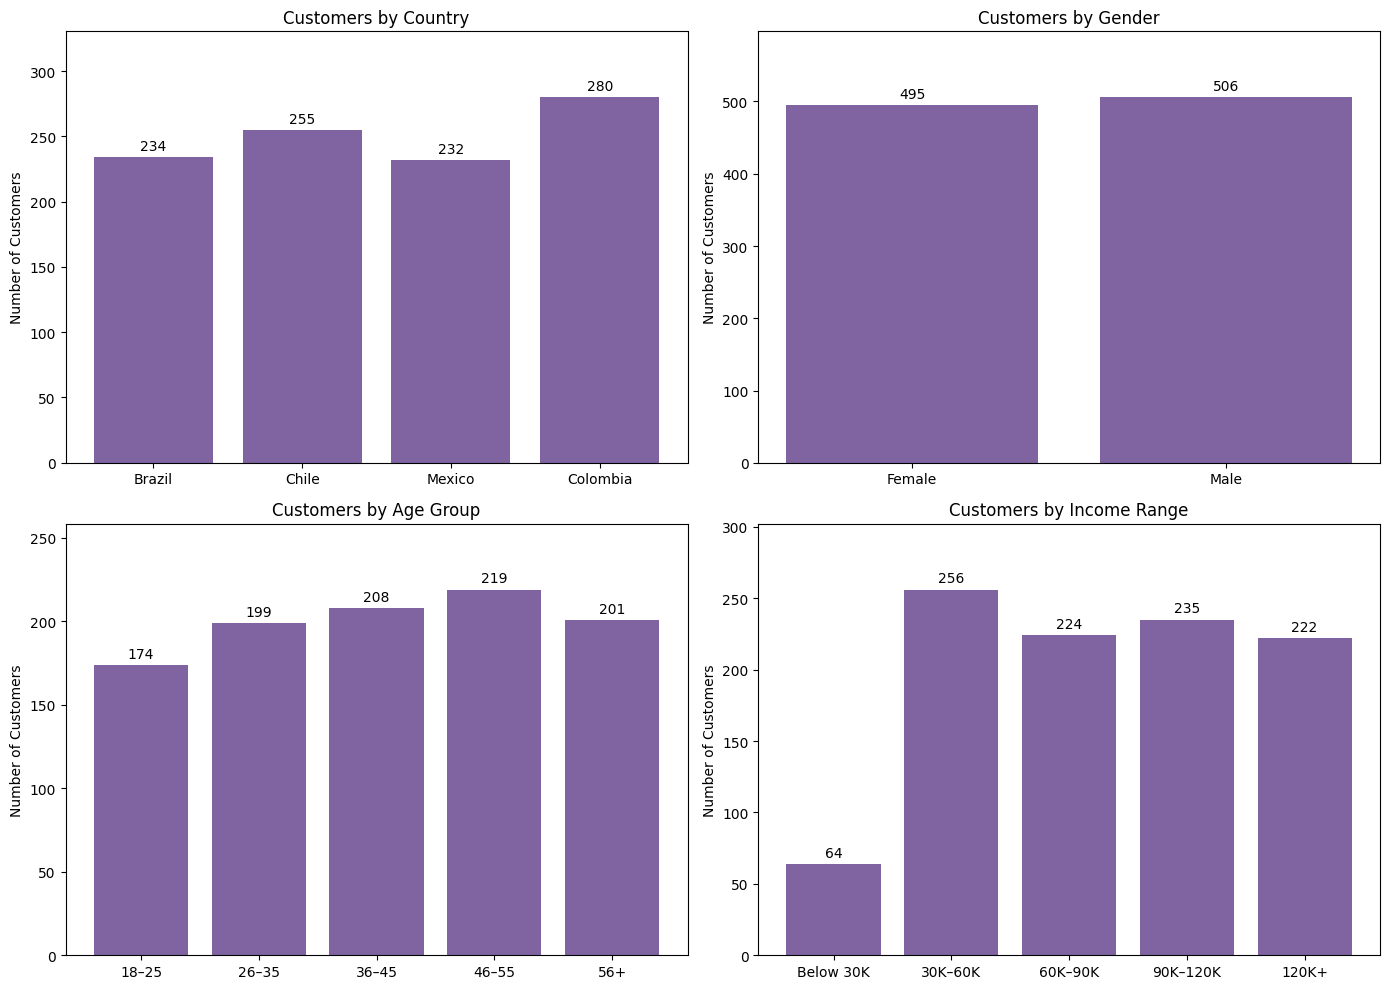

In [40]:
# Customer-level data: one row per customer
group_columns = ["country", "gender", "age_group", "income_group"]

# Display customer counts and percentages
for column in group_columns:
    counts = customers_clean[column].value_counts(sort=False)

    summary = counts.to_frame(name="Customer Count")
    summary["Percentage (%)"] = (
        counts / len(customers_clean) * 100
    ).round(2)

    print(f"\nCustomer distribution by {column}:")
    display(summary)

# Visualise the four distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

titles = [
    "Customers by Country",
    "Customers by Gender",
    "Customers by Age Group",
    "Customers by Income Range"
]

for ax, column, title in zip(
    axes.flat, group_columns, titles
):
    counts = customers_clean[column].value_counts(sort=False)

    bars = ax.bar(
        counts.index.astype(str),
        counts.values,
        color="#8064A2"
    )

    ax.set_title(title)
    ax.set_ylabel("Number of Customers")
    ax.set_ylim(0, counts.max() * 1.18)
    ax.bar_label(bars, padding=3)

    if column == "income_group":
        ax.tick_params(axis="x")

plt.tight_layout()
plt.show()

**Observations**

---



- Customers are distributed across four countries. Colombia
  has the largest share (27.97%), while Mexico has the
  smallest share (23.18%).
- Gender representation is nearly equal: 50.55% male
  and 49.45% female.
- Across the current age groups, customer shares range
  from 17.38% to 21.88%, indicating relatively similar group sizes.
- The Below 30K income group accounts for 6.39% of customers,
  while the other income groups each account for 22.18%–25.57%.


### **3.2 Numerical Distributions and Outlier Detection**

Examine the distributions of price, quantity, discount, sales
before tax, customer age and income using histograms and boxplots.

Points outside the boxplot whiskers are potential outliers.


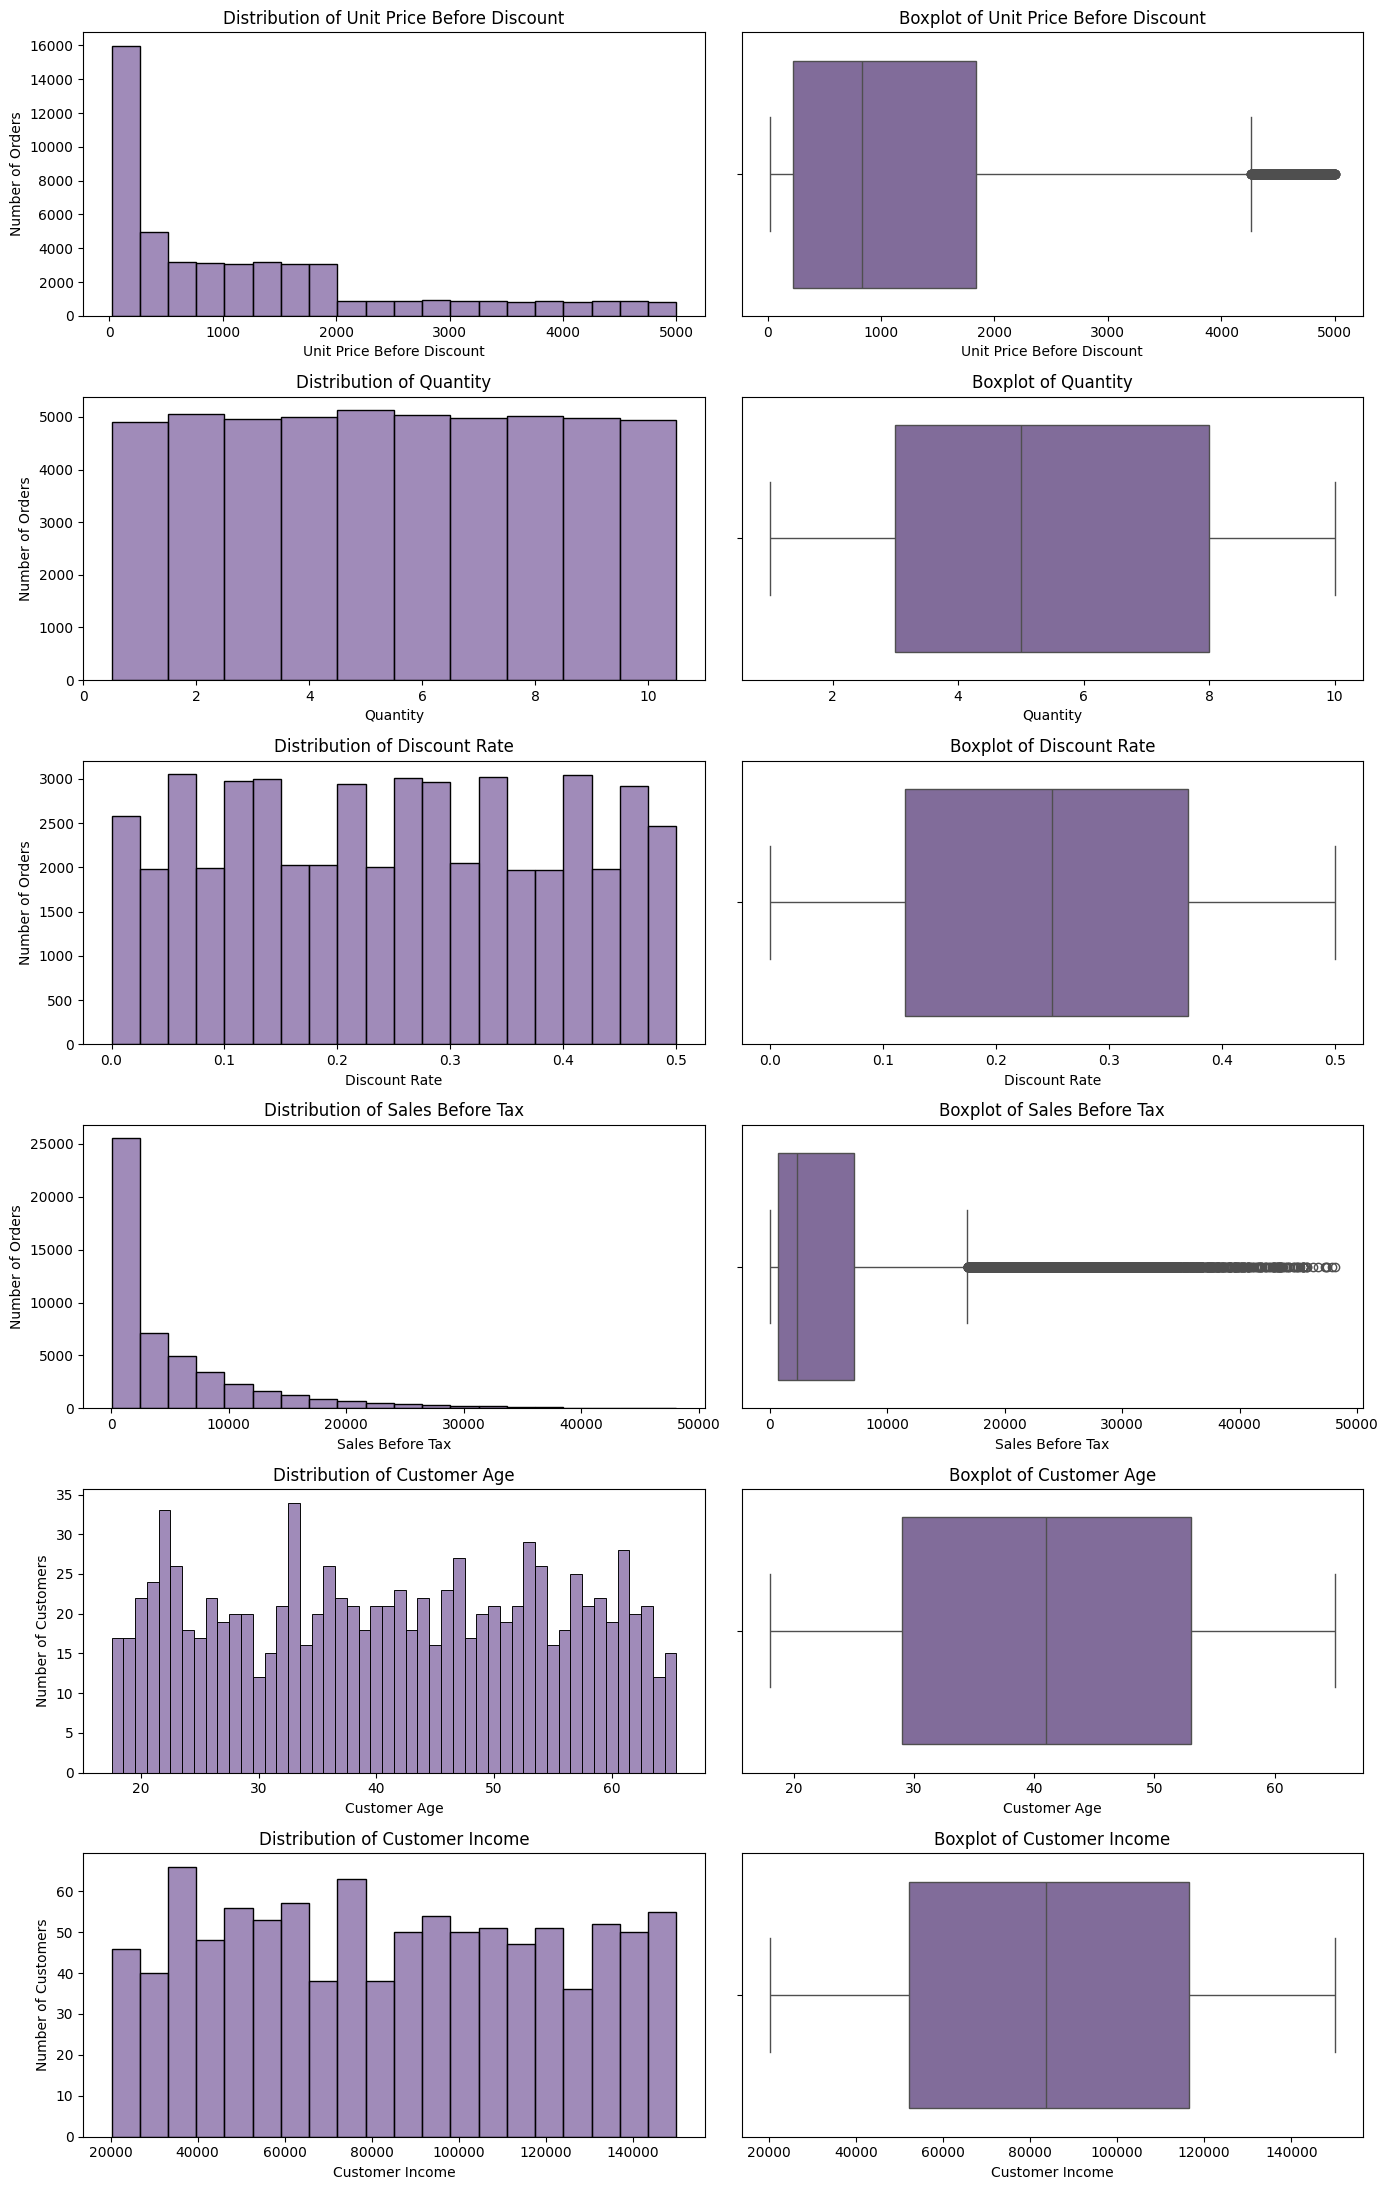

In [41]:
# Select the appropriate data source for each variable
variables = [
    (retail_data, "price", "Unit Price Before Discount"),
    (retail_data, "quantity", "Quantity"),
    (retail_data, "discount", "Discount Rate"),
    (retail_data, "sales_before_tax", "Sales Before Tax"),
    (customers_clean, "age", "Customer Age"),
    (customers_clean, "income", "Customer Income")
]

# Create one histogram and one boxplot for each variable
fig, axes = plt.subplots(6, 2, figsize=(14, 22))

for row, (table, column, title) in enumerate(variables):
    values = table[column].dropna()
    count_label = (
        "Number of Customers"
        if column in ["age", "income"]
        else "Number of Orders"
    )

    # Histogram: show the distribution
    sns.histplot(
        x=values,
        bins=20,
        discrete=(column in ["quantity", "age"]),
        color="#8064A2",
        ax=axes[row, 0]
    )

    axes[row, 0].set_title(f"Distribution of {title}")
    axes[row, 0].set_xlabel(title)
    axes[row, 0].set_ylabel(count_label)

    # Boxplot: show median, spread and potential outliers
    sns.boxplot(
        x=values,
        color="#8064A2",
        ax=axes[row, 1]
    )

    axes[row, 1].set_title(f"Boxplot of {title}")
    axes[row, 1].set_xlabel(title)

plt.tight_layout()
plt.show()

**Observations**

---



- Unit price and sales before tax are right-skewed.Lower unit prices and smaller order amounts are more common. A smaller number of records have very high values.
- Boxplots flag high unit prices and high sales amounts
  as potential outliers.
- Quantity and discount values are relatively evenly
  distributed across their observed ranges.
- Customer age and income are broadly distributed, with
  no potential outliers visible in their boxplots.
- High-value records were reviewed, and no obvious errors
  were identified. Retained for subsequent analysis.


### **3.3 Correlation Analysis**

Examine Pearson correlations among key variables (Unit Price, Quantity, Discount, Sales Before Tax, Shipping Cost, and Days to Ship) to evaluate linear relationships:

,price,quantity,discount,sales_before_tax,shipping_cost,days_to_ship
price,1.000,0.002,0.001,0.787,0.008,0.003
quantity,0.002,1.000,-0.001,0.398,-0.000,-0.007
discount,0.001,-0.001,1.000,-0.148,-0.000,-0.005
sales_before_tax,0.787,0.398,-0.148,1.000,0.006,0.002
shipping_cost,0.008,-0.000,-0.000,0.006,1.000,0.002
days_to_ship,0.003,-0.007,-0.005,0.002,0.002,1.000


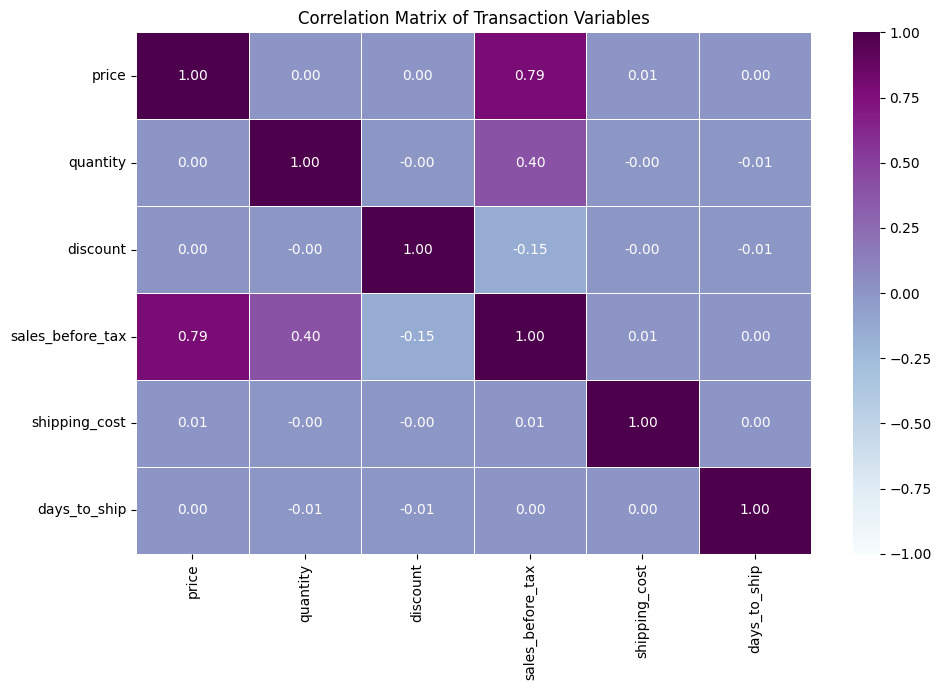

In [42]:
# Select transaction-level numerical variables
correlation_columns = [
    "price",
    "quantity",
    "discount",
    "sales_before_tax",
    "shipping_cost",
    "days_to_ship"
]

# Calculate Pearson correlations
correlation_matrix = retail_data[correlation_columns].corr()

display(correlation_matrix.round(3))

# Plot the correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="BuPu",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Transaction Variables")
plt.tight_layout()
plt.show()

**Observations**

---



- Unit price has a strong positive correlation with sales
  before tax (0.787).
- Quantity is positively correlated with sales before tax
  (0.398), while discount has a weak negative correlation
  with sales before tax (-0.148).
- Discount and quantity show almost no linear correlation
  (-0.001) across all orders.
- Correlations involving sales before tax partly reflect its
  calculation from price, quantity and discount.


## **4. Business Analysis**

Analyse sales trends, customer purchasing behaviour, customer value,
product performance and discount relationships to identify opportunities
for marketing and product decisions.

### **4.1 Objective 1: Sales Trends and Seasonal Patterns**

Examine monthly sales revenue, order volume, quantities sold and average order value to identify sales trends.

Use the complete calendar years 2020–2022 for annual comparisons and
seasonal analysis, as 2019 and 2023 contain only partial-year records.

Sales Before Tax is used as the main revenue measure.



#### **4.1.1 Monthly Sales Trends**

In [43]:
# Summarise monthly sales using the full dataset
monthly_sales = (
    retail_data
    .groupby(retail_data["order_date"].dt.to_period("M"))
    .agg(
        sales_revenue=("sales_before_tax", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .sort_index()
)

# Calculate monthly average order value
monthly_sales["average_order_value"] = (
    monthly_sales["sales_revenue"]
    / monthly_sales["total_orders"]
)

monthly_sales.index.name = "month"

# Preview the first five months
display(monthly_sales.head().round(2))

,sales_revenue,total_orders,units_sold,average_order_value
month,,,,
2019-08,3465168.77,694,4003,4993.04
2019-09,5795560.19,1163,6152,4983.28
2019-10,7419917.03,1309,7104,5668.39
2019-11,6042039.25,1217,6804,4964.70
2019-12,6791918.48,1231,6710,5517.40


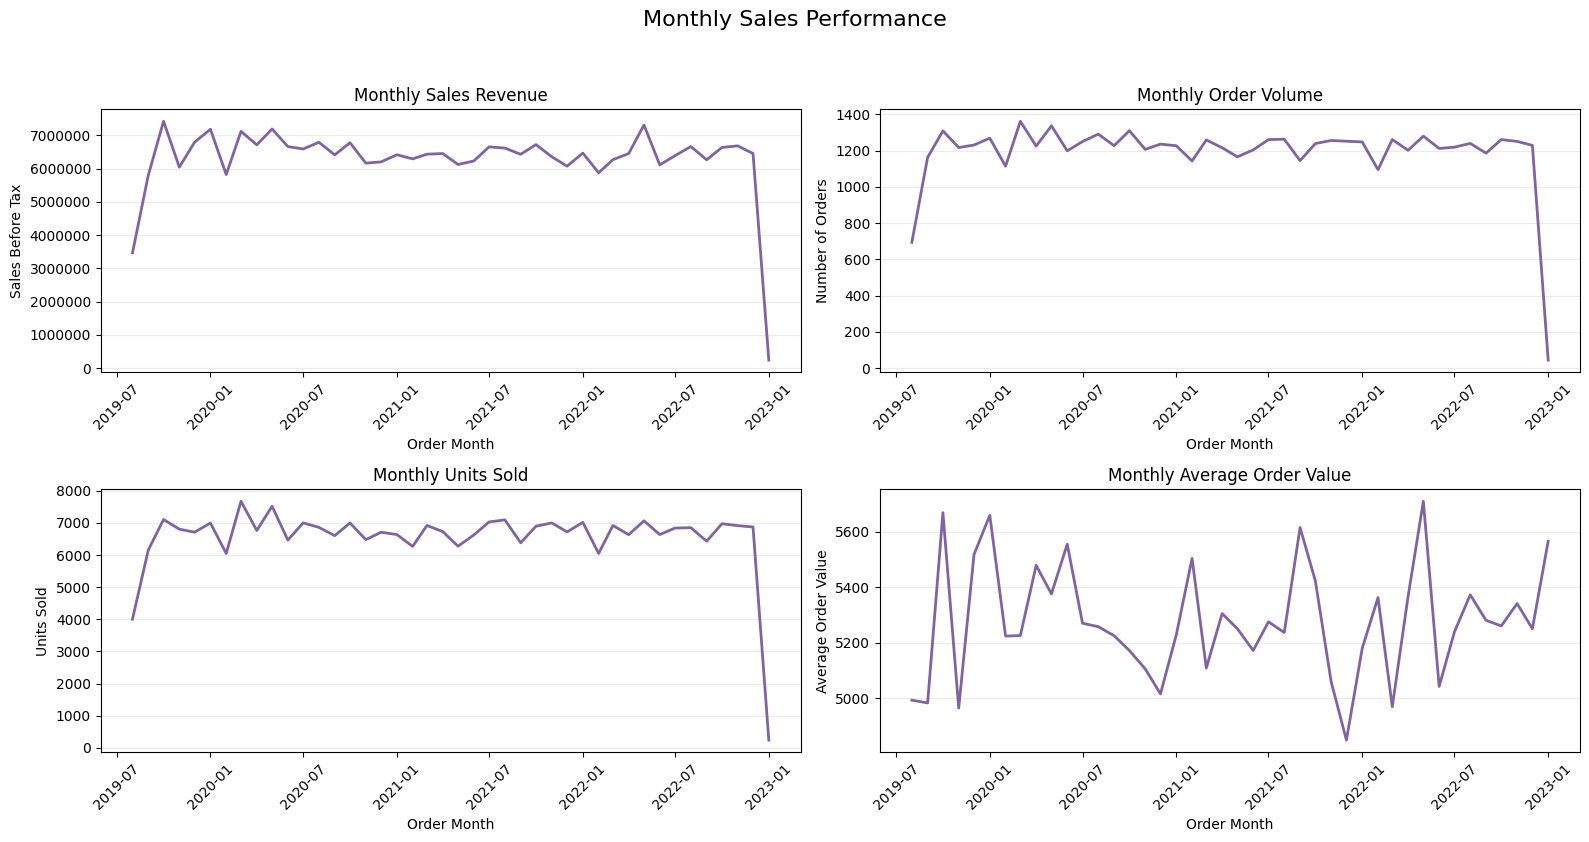

Monthly summary excluding partial months:


,sales_revenue,total_orders,units_sold,average_order_value
min,"5,795,560","1,095","6,048","4,849"
max,"7,419,917","1,362","7,672","5,709"
mean,"6,499,457","1,232","6,766","5,277"


In [44]:
# Convert the monthly index to dates for plotting
plot_dates = monthly_sales.index.to_timestamp()

metrics = [
    ("sales_revenue", "Monthly Sales Revenue", "Sales Before Tax"),
    ("total_orders", "Monthly Order Volume", "Number of Orders"),
    ("units_sold", "Monthly Units Sold", "Units Sold"),
    ("average_order_value", "Monthly Average Order Value",
     "Average Order Value")
]

fig, axes = plt.subplots(2, 2, figsize=(16, 9))

for ax, (column, title, ylabel) in zip(axes.flat, metrics):
    ax.plot(
        plot_dates,
        monthly_sales[column],
        color="#8064A2",
        linewidth=2
    )
    ax.set_title(title)
    ax.set_xlabel("Order Month")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=45)
    ax.ticklabel_format(axis="y", style="plain")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Monthly Sales Performance", fontsize=16)


plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()

# Summarise complete months only
complete_months = monthly_sales.loc["2019-09":"2022-12"]

print("Monthly summary excluding partial months:")

# Create the monthly summary
monthly_summary = complete_months[
    ["sales_revenue", "total_orders",
     "units_sold", "average_order_value"]
].agg(["min", "max", "mean"])

# Display all values as whole numbers
display(monthly_summary.style.format("{:,.0f}"))



**Observations**

---

- August 2019 and January 2023 are partial months. Their lower sales,
  order counts and quantities should not be interpreted as evidence
  of declining business performance.

- Across complete months, sales revenue, order volume and units sold
  fluctuate within relatively stable ranges, with no clear sustained
  upward or downward trend.

- Across complete months, monthly sales revenue ranges from approximately 5.80 million to 7.42 million, with 1,095–1,362 orders.
- Over the same period, monthly units sold range from 6,048 to 7,672, while monthly average order value ranges from 4,849 to 5,709，with no clear sustained upward or downward trend. This suggests that monthly sales revenue is primarily driven by order volume rather than changes in spending per order.


#### **4.1.2 Annual Sales Comparison**

Compare sales revenue, order volume, units sold and average order value
across the complete calendar years 2020–2022. Calculate year-over-year
sales growth to assess changes in annual performance.

,sales_revenue,total_orders,units_sold,average_order_value,sales_growth_pct
year,,,,,
2020,"79,600,805","15,027","82,108","5,297",—
2021,"76,776,468","14,631","80,566","5,248",-3.55%
2022,"77,551,569","14,684","81,191","5,281",+1.01%


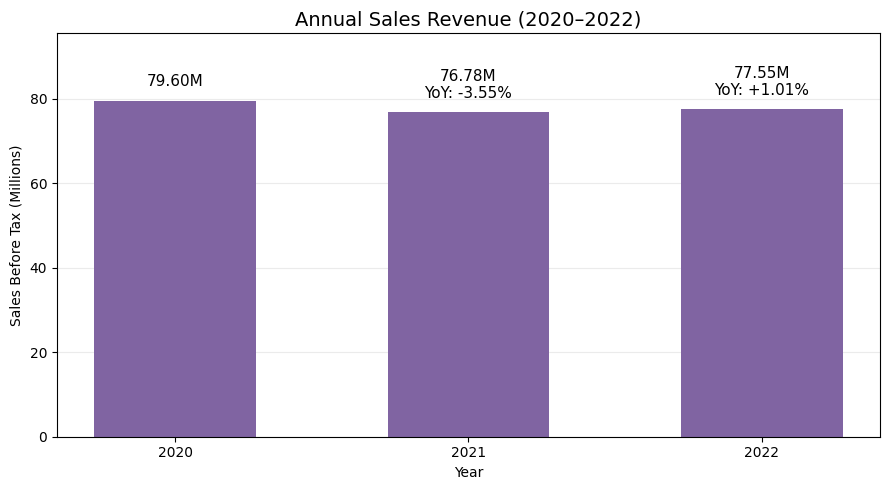

In [45]:
# Select complete calendar years: 2020–2022
annual_data = retail_data.loc[
    retail_data["order_date"].dt.year.between(2020, 2022)
].copy()

# Summarise annual sales performance
annual_sales = (
    annual_data
    .groupby(annual_data["order_date"].dt.year)
    .agg(
        sales_revenue=("sales_before_tax", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .sort_index()
)

annual_sales.index.name = "year"

# Calculate average order value
annual_sales["average_order_value"] = (
    annual_sales["sales_revenue"]
    / annual_sales["total_orders"]
)

# Calculate year-over-year sales growth
annual_sales["sales_growth_pct"] = (
    annual_sales["sales_revenue"].pct_change() * 100
)

# Format the output
display(
    annual_sales.style.format({
        "sales_revenue": "{:,.0f}",
        "total_orders": "{:,.0f}",
        "units_sold": "{:,.0f}",
        "average_order_value": "{:,.0f}",
        "sales_growth_pct": "{:+.2f}%"
    }, na_rep="—")
)

# Plot annual sales revenue in millions
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    annual_sales.index.astype(str),
    annual_sales["sales_revenue"] / 1_000_000,
    color="#8064A2",
    width=0.55
)

# Add revenue and year-over-year growth labels
for bar, (_, row) in zip(bars, annual_sales.iterrows()):
    label = f"{row['sales_revenue'] / 1_000_000:.2f}M"

    if pd.notna(row["sales_growth_pct"]):
        label += f"\nYoY: {row['sales_growth_pct']:+.2f}%"

    ax.annotate(
        label,
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title("Annual Sales Revenue (2020–2022)", fontsize=14)
ax.set_xlabel("Year")
ax.set_ylabel("Sales Before Tax (Millions)")
ax.set_ylim(0, annual_sales["sales_revenue"].max() / 1_000_000 * 1.2)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Observations**

- Sales revenue falls by 3.55%, from 79.60 million in 2020 to
  76.78 million in 2021. Order volume, units sold and average order
  value also decrease.

- In 2022, sales revenue rises by 1.01% to 77.55 million, accompanied
  by small increases in order volume, units sold and average order value.

- Despite this recovery, all four measures remain below their
  2020 levels.

#### **4.1.3 Seasonal Patterns**

Compare monthly sales revenue across 2020–2022 to examine whether
peaks and troughs recur in the same months across years.

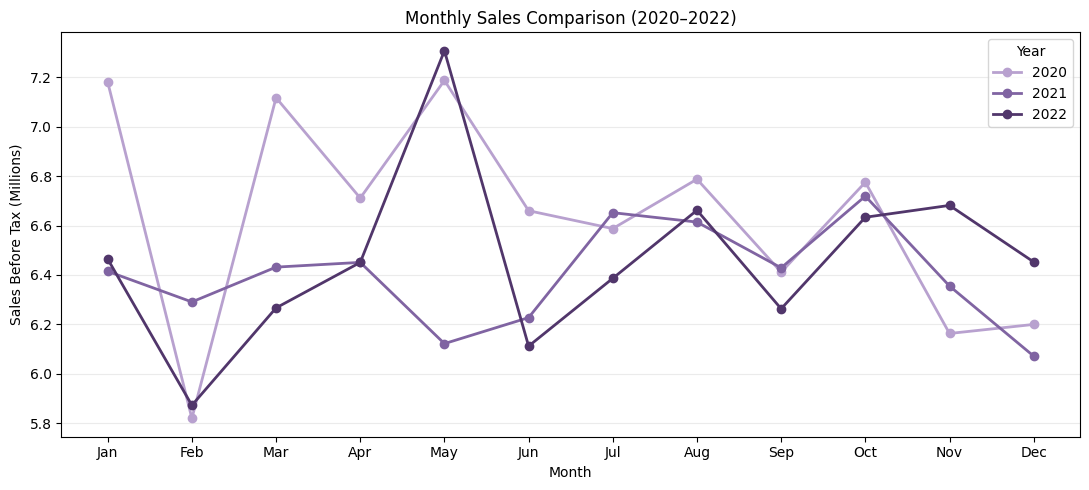

In [46]:
# Arrange monthly revenue by month and year
seasonal_data = annual_data.assign(
    year=annual_data["order_date"].dt.year,
    month=annual_data["order_date"].dt.month
)

seasonal_sales = seasonal_data.pivot_table(
    index="month",
    columns="year",
    values="sales_before_tax",
    aggfunc="sum"
).sort_index()

# Compare the three complete years
ax = (seasonal_sales / 1_000_000).plot(
    figsize=(11, 5),
    marker="o",
    linewidth=2,
    color=["#B8A1CF", "#8064A2", "#51366B"]
)

ax.set_title("Monthly Sales Comparison (2020–2022)")
ax.set_xlabel("Month")
ax.set_ylabel("Sales Before Tax (Millions)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])
ax.legend(title="Year")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

**Observations**

---



- May records the highest monthly sales in 2020 and 2022,
  while July records the highest sales in 2021. Peak sales
  therefore do not occur consistently in the same month.

- February records the lowest sales in 2020 and 2022.
  However, its shorter calendar length may partly explain
  the lower monthly totals.

- Sales decrease from August to September and rise again
  in October in all three years, suggesting a recurring
  pattern that warrants further investigation.

- Overall, the chart provides limited evidence of stable
  seasonality.

#### **4.1.4 Objective 1: Summary of Key Findings**
Sales performance shows monthly fluctuations without a clear sustained
growth trend. Revenue, order volume and units sold decline in 2021
and recover slightly in 2022, but remain below 2020 levels.

The monthly comparisons provide limited evidence of consistent
seasonal patterns.For sales planning purposes, businesses should use recent sales and order volumes as the baseline and conduct regular performance reviews, instead of relying on assumptions of fixed annual peak seasons.


### **4.2 Objective 2: Customer Demographic and Geographic Analysis**

Compare sales revenue and purchasing behaviour across countries,
age groups, gender and income groups to identify opportunities
for targeted marketing.


#### **4.2.1 Sales Performance by Country**

Compare sales revenue, purchasing customer counts, order volume,
average order value and sales per purchasing customer across
the four markets using the full dataset.

,sales_revenue,purchasing_customers,total_orders,units_sold,average_order_value,sales_per_customer,sales_share_pct
country,,,,,,,
Colombia,"74,366,208",279,"13,950","76,013","5,331","266,546",28.20%
Chile,"66,808,517",255,"12,750","70,073","5,240","261,994",25.34%
Mexico,"61,723,652",232,"11,600","63,880","5,321","266,050",23.41%
Brazil,"60,789,961",234,"11,700","64,912","5,196","259,786",23.05%


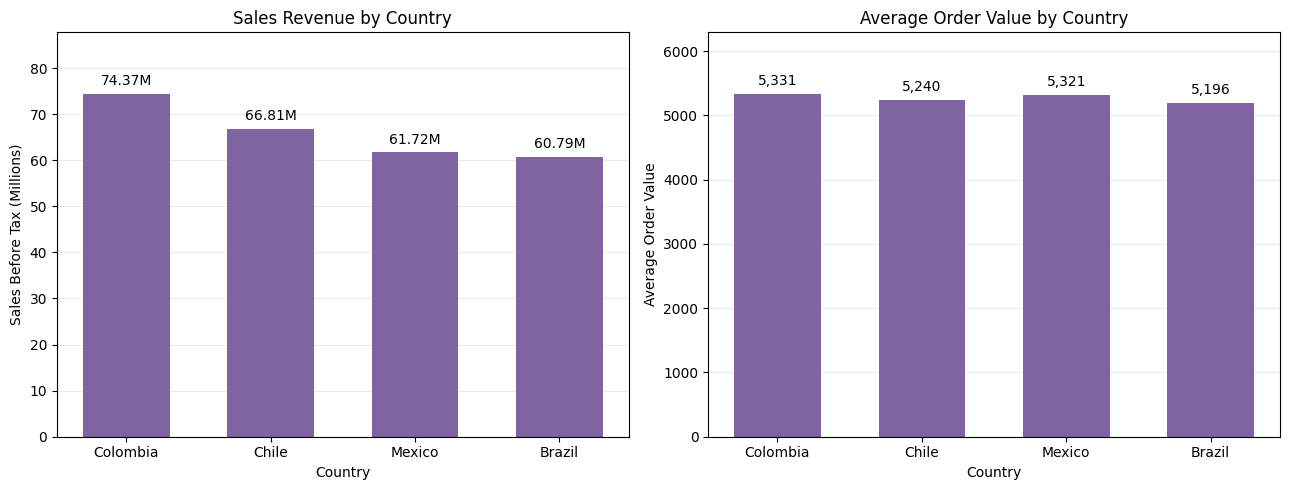

In [47]:
# Summarise country performance
country_summary = (
    retail_data.groupby("country")
    .agg(
        sales_revenue=("sales_before_tax", "sum"),
        purchasing_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum")
    )
)

# Calculate spending metrics
country_summary["average_order_value"] = (
    country_summary["sales_revenue"]
    / country_summary["total_orders"]
)

country_summary["sales_per_customer"] = (
    country_summary["sales_revenue"]
    / country_summary["purchasing_customers"]
)

country_summary["sales_share_pct"] = (
    country_summary["sales_revenue"]
    / country_summary["sales_revenue"].sum() * 100
)

# Sort countries by sales revenue
country_summary = country_summary.sort_values(
    "sales_revenue", ascending=False
)

# Display amounts and counts as whole numbers
country_formats = {
    column: "{:,.0f}"
    for column in country_summary.columns
}
country_formats["sales_share_pct"] = "{:.2f}%"

display(country_summary.style.format(country_formats))

# Plot sales revenue and average order value
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics = [
    (
        "sales_revenue",
        "Sales Revenue by Country",
        "Sales Before Tax (Millions)",
        1_000_000
    ),
    (
        "average_order_value",
        "Average Order Value by Country",
        "Average Order Value",
        1
    )
]

for ax, (column, title, ylabel, divisor) in zip(axes, metrics):
    values = country_summary[column] / divisor

    bars = ax.bar(
        country_summary.index,
        values,
        color="#8064A2",
        width=0.6
    )

    # Add value labels
    labels = [
        f"{value:.2f}M" if divisor == 1_000_000
        else f"{value:,.0f}"
        for value in values
    ]

    ax.bar_label(bars, labels=labels, padding=4)
    ax.set_title(title)
    ax.set_xlabel("Country")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, values.max() * 1.18)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Observations**

---



- Colombia generates the highest sales revenue before tax, contributing
28.20% of total sales, followed by Chile, Mexico and Brazil.
- Average order values are relatively similar across countries, ranging from
5,196 in Brazil to 5,331 in Colombia. The narrow gap indicates that differences in total sales therefore mainly reflect order volume and purchasing customer base size rather than large differences in spending per order.
- These findings may suggest that marketing opportunities exist in lower‑revenue markets such as Brazil to expand the active customer base and lift total sales, while Colombia can be prioritised for retention campaigns to protect this top revenue source.

#### **4.2.2 Sales Performance by Age Group**

Compare sales revenue, purchasing customer counts and average order
value across age groups to identify differences in sales contribution
and spending per order.

,sales_revenue,purchasing_customers,total_orders,units_sold,average_order_value,sales_per_customer,sales_share_pct
age_group,,,,,,,
18–25,"45,511,076",174,"8,700","47,510","5,231","261,558",17.26%
26–35,"52,385,895",199,"9,950","54,657","5,265","263,246",19.87%
36–45,"53,463,642",207,"10,350","56,613","5,166","258,278",20.28%
46–55,"58,711,625",219,"10,950","60,284","5,362","268,090",22.27%
56+,"53,616,101",201,"10,050","55,814","5,335","266,747",20.33%


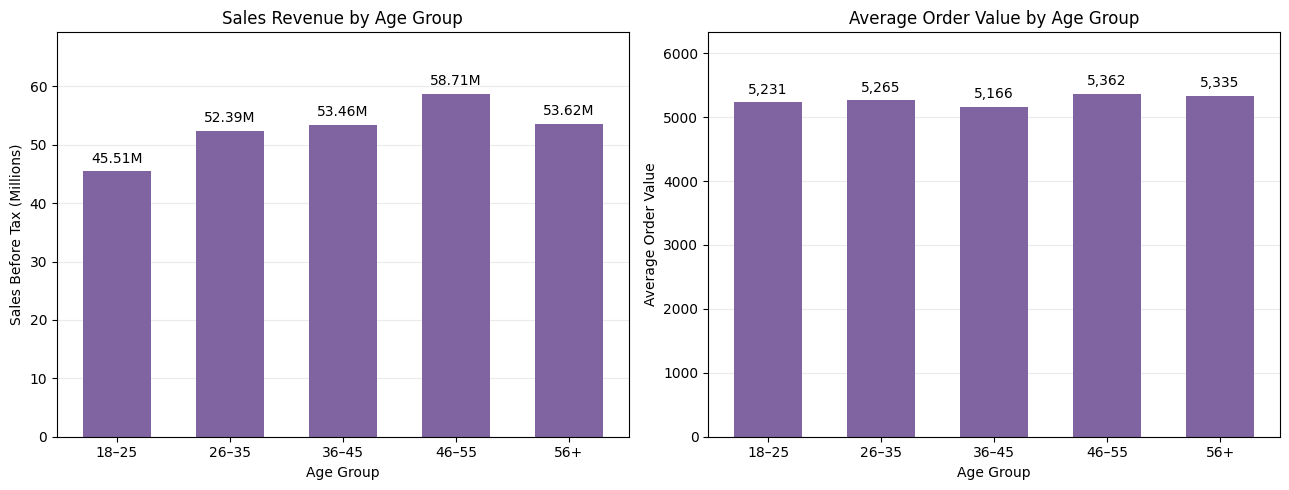

In [48]:
# Summarise sales performance by age group
age_summary = (
    retail_data.groupby("age_group", observed=True)
    .agg(
        sales_revenue=("sales_before_tax", "sum"),
        purchasing_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .sort_index()
)

# Calculate spending metrics
age_summary["average_order_value"] = (
    age_summary["sales_revenue"]
    / age_summary["total_orders"]
)

age_summary["sales_per_customer"] = (
    age_summary["sales_revenue"]
    / age_summary["purchasing_customers"]
)

age_summary["sales_share_pct"] = (
    age_summary["sales_revenue"]
    / age_summary["sales_revenue"].sum() * 100
)

# Display the summary table
age_formats = {
    column: "{:,.0f}"
    for column in age_summary.columns
}
age_formats["sales_share_pct"] = "{:.2f}%"

display(age_summary.style.format(age_formats))

# Plot sales revenue and average order value
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics = [
    (
        "sales_revenue",
        "Sales Revenue by Age Group",
        "Sales Before Tax (Millions)",
        1_000_000
    ),
    (
        "average_order_value",
        "Average Order Value by Age Group",
        "Average Order Value",
        1
    )
]

for ax, (column, title, ylabel, divisor) in zip(axes, metrics):
    values = age_summary[column] / divisor

    bars = ax.bar(
        age_summary.index.astype(str),
        values,
        color="#8064A2",
        width=0.6
    )

    labels = [
        f"{value:.2f}M" if divisor == 1_000_000
        else f"{value:,.0f}"
        for value in values
    ]

    ax.bar_label(bars, labels=labels, padding=4)
    ax.set_title(title)
    ax.set_xlabel("Age Group")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, values.max() * 1.18)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Observations**

---



- The 46–55 age group generates the highest sales revenue at
  58.71 million (22.27% of total sales). It also has the largest
  purchasing customer base, with 219 customers, and the highest
  average order value of 5,362.

- The 18–25 group contributes the lowest sales revenue at
  45.51 million (17.26%) and has the fewest purchasing customers,
  with 174 customers. However, its average order value is not
  the lowest.

- Average order values are relatively similar across age groups,
  ranging from 5,166 for ages 36–45 to 5,362 for ages 46–55.
  Revenue differences mainly reflect customer base size and
  total order volume rather than large differences in spending
  per order.

- Maintaining engagement with the 46–55 group may help protect
  its substantial sales contribution. Opportunities to attract
  18–25 shoppers could be explored further,

#### **4.2.3 Sales Performance by Gender**

Compare sales revenue, purchasing customer counts and average order
value by gender to examine differences in sales contribution and
spending per order.

,sales_revenue,purchasing_customers,total_orders,units_sold,average_order_value,sales_per_customer,sales_share_pct
gender,,,,,,,
Female,"130,909,475",494,"24,700","136,064","5,300","264,999",49.65%
Male,"132,778,864",506,"25,300","138,814","5,248","262,409",50.35%


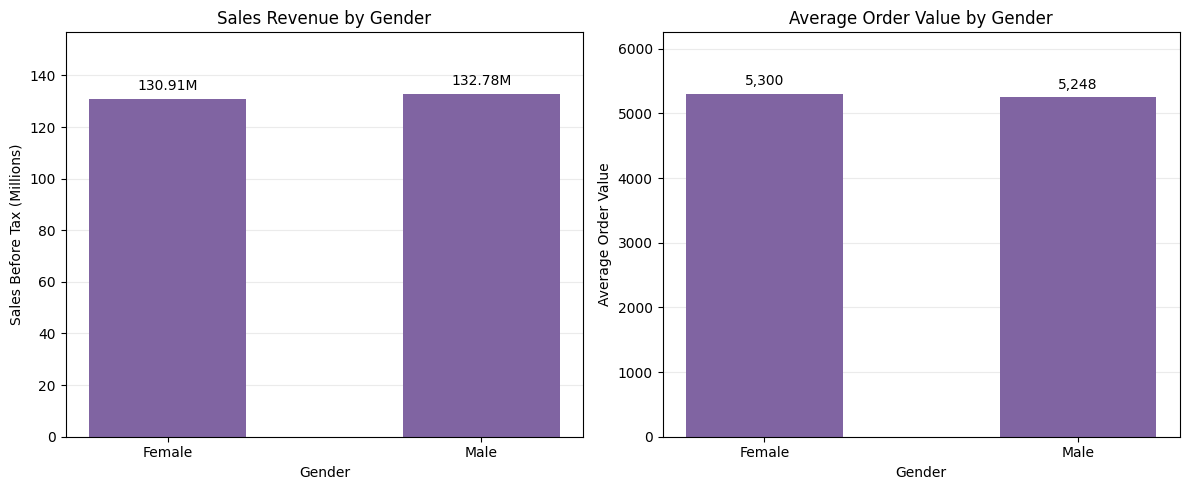

In [49]:
# Summarise sales performance by gender
gender_summary = (
    retail_data.groupby("gender")
    .agg(
        sales_revenue=("sales_before_tax", "sum"),
        purchasing_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .sort_index()
)

# Calculate spending metrics
gender_summary["average_order_value"] = (
    gender_summary["sales_revenue"]
    / gender_summary["total_orders"]
)

gender_summary["sales_per_customer"] = (
    gender_summary["sales_revenue"]
    / gender_summary["purchasing_customers"]
)

gender_summary["sales_share_pct"] = (
    gender_summary["sales_revenue"]
    / gender_summary["sales_revenue"].sum() * 100
)

# Display the summary table
gender_formats = {
    column: "{:,.0f}"
    for column in gender_summary.columns
}
gender_formats["sales_share_pct"] = "{:.2f}%"

display(gender_summary.style.format(gender_formats))

# Plot sales revenue and average order value
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metrics = [
    (
        "sales_revenue",
        "Sales Revenue by Gender",
        "Sales Before Tax (Millions)",
        1_000_000
    ),
    (
        "average_order_value",
        "Average Order Value by Gender",
        "Average Order Value",
        1
    )
]

for ax, (column, title, ylabel, divisor) in zip(axes, metrics):
    values = gender_summary[column] / divisor

    bars = ax.bar(
        gender_summary.index.astype(str),
        values,
        color="#8064A2",
        width=0.5
    )

    labels = [
        f"{value:.2f}M" if divisor == 1_000_000
        else f"{value:,.0f}"
        for value in values
    ]

    ax.bar_label(bars, labels=labels, padding=4)
    ax.set_title(title)
    ax.set_xlabel("Gender")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, values.max() * 1.18)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Observations**

---



- Male customers contribute 132.78 million in sales revenue
  (50.35%), compared with 130.91 million (49.65%) from female
  customers, indicating a nearly equal sales contribution.

- The male purchasing customer base is slightly larger, with
  506 customers compared with 494 female customers, and records
  more total orders.

- Female customers have a slightly higher average order value
  of approximately 5,300, compared with 5,248 for male customers.
  Higher total sales from male customers therefore do not
  indicate higher spending per order.

- Overall, the aggregate results show relatively small differences
in spending per order between genders. These findings alone provide
limited support for prioritising gender-based marketing.

#### **4.2.4 Sales Performance by Income Group**

Compare sales revenue, purchasing customer counts and average order
value across income groups. Consider differences in group size when
interpreting sales contributions, and examine whether higher income
groups consistently record higher spending per order.

,sales_revenue,purchasing_customers,total_orders,units_sold,average_order_value,sales_per_customer,sales_share_pct
income_group,,,,,,,
Below 30K,"15,961,264",63,"3,150","16,838","5,067","253,353",6.05%
30K–60K,"68,524,536",256,"12,800","71,012","5,353","267,674",25.99%
60K–90K,"57,953,514",224,"11,200","61,317","5,174","258,721",21.98%
90K–120K,"61,285,356",235,"11,750","64,352","5,216","260,789",23.24%
120K+,"59,963,669",222,"11,100","61,359","5,402","270,107",22.74%


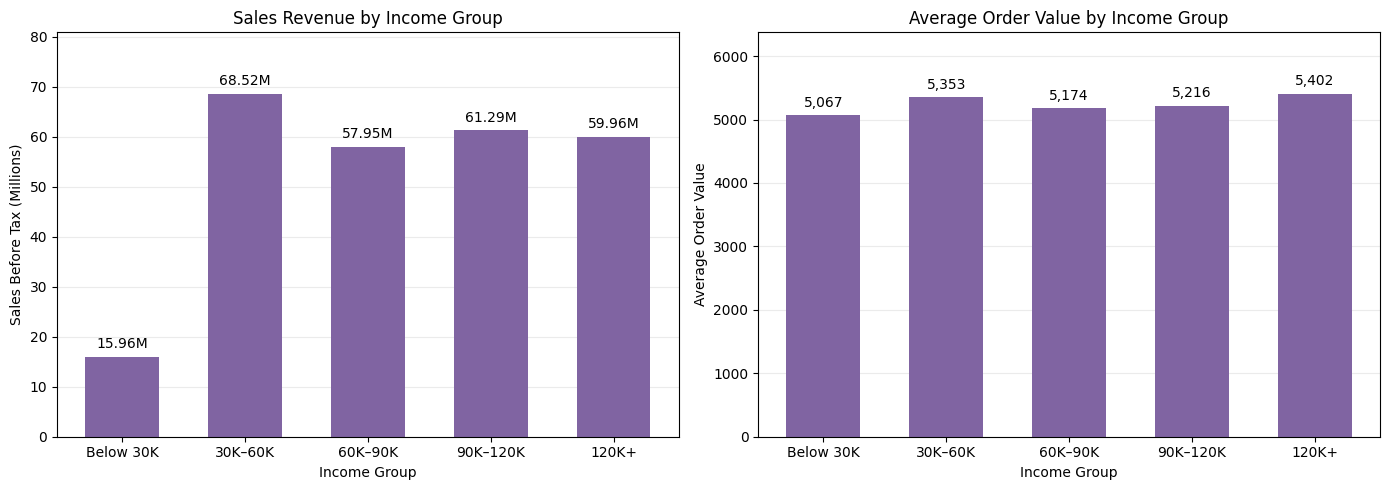

In [50]:
# Summarise sales performance by income group
income_summary = (
    retail_data.groupby("income_group", observed=True)
    .agg(
        sales_revenue=("sales_before_tax", "sum"),
        purchasing_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum")
    )
    .sort_index()
)

# Calculate spending metrics
income_summary["average_order_value"] = (
    income_summary["sales_revenue"]
    / income_summary["total_orders"]
)

income_summary["sales_per_customer"] = (
    income_summary["sales_revenue"]
    / income_summary["purchasing_customers"]
)

income_summary["sales_share_pct"] = (
    income_summary["sales_revenue"]
    / income_summary["sales_revenue"].sum() * 100
)

# Display the summary table
income_formats = {
    column: "{:,.0f}"
    for column in income_summary.columns
}
income_formats["sales_share_pct"] = "{:.2f}%"

display(income_summary.style.format(income_formats))

# Plot sales revenue and average order value
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metrics = [
    (
        "sales_revenue",
        "Sales Revenue by Income Group",
        "Sales Before Tax (Millions)",
        1_000_000
    ),
    (
        "average_order_value",
        "Average Order Value by Income Group",
        "Average Order Value",
        1
    )
]

for ax, (column, title, ylabel, divisor) in zip(axes, metrics):
    values = income_summary[column] / divisor

    bars = ax.bar(
        income_summary.index.astype(str),
        values,
        color="#8064A2",
        width=0.6
    )

    labels = [
        f"{value:.2f}M" if divisor == 1_000_000
        else f"{value:,.0f}"
        for value in values
    ]

    ax.bar_label(bars, labels=labels, padding=4)
    ax.set_title(title)
    ax.set_xlabel("Income Group")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, values.max() * 1.18)
    ax.tick_params(axis="x")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Observations**

---



- The 30K–60K income group generates the highest sales revenue
  at 68.52 million (25.99% of total sales) and records the highest number
of purchasing customers, orders and units sold.

- The Below 30K group contributes the lowest sales revenue
  at 15.96 million (6.05%) and has only 63 purchasing customers.
  Its lower sales contribution should be considered alongside
  its smaller customer base.

- The 120K+ group records the highest average order value
  at approximately 5,402, compared with 5,067 for the Below 30K
  group. However, average order value does not increase
  consistently across successive income groups.

- Marketing decisions should consider actual spending and product
  preferences alongside income. These results alone do not support
  assuming that higher-income customers always spend more per order.

#### **4.2.5 Objective 2: Summary of Key Findings**
Colombia generates the highest sales revenue among the four markets,
followed by Chile, Mexico and Brazil. Average order values are relatively
similar across countries, indicating that revenue differences mainly
reflect purchasing customer counts and total order volume.

The 46–55 age group and the 30K–60K income group contribute the highest
sales within their respective comparisons. Gender contributions are
nearly balanced. Average order value does not increase consistently
with age or income, although the 120K+ income group records the highest
spending per order.

These separate comparisons identify important existing sales
contributors, but do not establish a single combined high-value
customer profile. Demographics alone provide limited support for
marketing priorities and should be combined with actual spending,
recent purchasing activity and product preferences.



### **4.3 Objective 3: Customer Value Segmentation**

Identify customer groups using total spending and recent purchase
activity to support customer engagement decisions. Average order
value is included as a descriptive metric.



#### **4.3.1 Customer Purchase Metrics**

Calculate each purchasing customer's total spending, number of orders,
average order value and days since their latest purchase.

Recency is measured relative to the day after the latest order date
in the dataset, rather than today's date. Customers without purchases
are excluded from these calculations and retained in the customer table.

,total_orders,total_spending,recency_days,average_order_value
count,"1,000","1,000","1,000","1,000"
mean,50,"263,688",25,"5,274"
std,0,"48,797",24,976
min,50,"122,541",1,"2,451"
25%,50,"228,824",7,"4,576"
50%,50,"262,189",17,"5,244"
75%,50,"294,625",35,"5,893"
max,50,"446,568",163,"8,931"


Minimum orders per customer: 50
Maximum orders per customer: 50


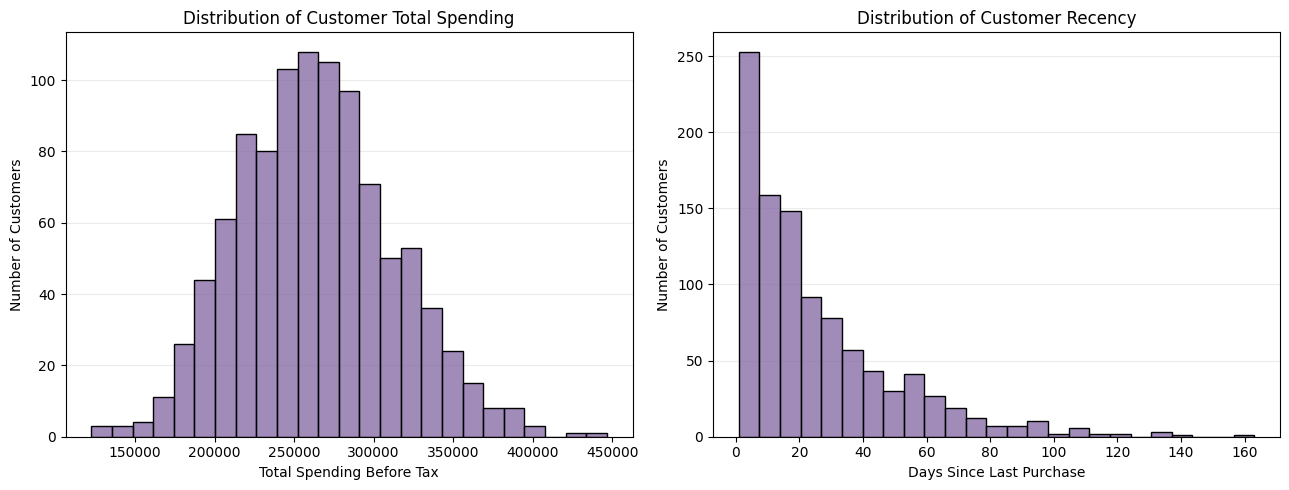

In [51]:
# Set a reference date based on the dataset
reference_date = (
    retail_data["order_date"].max() + pd.Timedelta(days=1)
)

# Create one row per purchasing customer
customer_metrics = (
    retail_data.groupby("customer_id")
    .agg(
        last_purchase_date=("order_date", "max"),
        total_orders=("order_id", "nunique"),
        total_spending=("sales_before_tax", "sum")
    )
    .reset_index()
)

# Calculate days since the latest purchase
customer_metrics["recency_days"] = (
    reference_date - customer_metrics["last_purchase_date"]
).dt.days

# Calculate average order value
customer_metrics["average_order_value"] = (
    customer_metrics["total_spending"]
    / customer_metrics["total_orders"]
)

# Review the distribution of customer metrics
display(
    customer_metrics[
        ["total_orders", "total_spending",
         "recency_days", "average_order_value"]
    ]
    .describe()
    .style.format("{:,.0f}")
)

# Check whether order counts vary between customers
print("Minimum orders per customer:",
      customer_metrics["total_orders"].min())
print("Maximum orders per customer:",
      customer_metrics["total_orders"].max())

# Plot customer spending and recency distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=customer_metrics,
    x="total_spending",
    bins=25,
    color="#8064A2",
    ax=axes[0]
)
axes[0].set_title("Distribution of Customer Total Spending")
axes[0].set_xlabel("Total Spending Before Tax")
axes[0].set_ylabel("Number of Customers")
axes[0].ticklabel_format(axis="x", style="plain")

sns.histplot(
    data=customer_metrics,
    x="recency_days",
    bins=25,
    color="#8064A2",
    ax=axes[1]
)
axes[1].set_title("Distribution of Customer Recency")
axes[1].set_xlabel("Days Since Last Purchase")
axes[1].set_ylabel("Number of Customers")

for ax in axes:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Observations**

---



- Customer metrics cover 1,000 purchasing customers. Every customer
  has exactly 50 orders, so total order count cannot distinguish
  purchasing frequency between customers in this dataset.

- Total spending ranges from approximately 122,541 to 446,568,
  with a median of 262,189. The middle 50% of customers spend
  approximately 228,824–294,625.

- Recency is right-skewed, with a median of 17 days and a maximum
  of 163 days. Most customers purchased relatively close to the
  reference date (2nd Jan 2023), while a smaller group has longer gaps since
  its last purchase.

- As every purchasing customer has 50 orders, average order value
  equals total spending divided by 50 and provides the same
  customer ranking. Subsequent segmentation will therefore use
  total spending and recency.

#### **4.3.2 Recency and Monetary Segmentation**

Divide purchasing customers into four groups using median total
spending and median recency as project-defined thresholds.

Higher spending includes customers at or above median total spending.
Recent includes customers whose recency is at or below median recency.
Customers with identical values are assigned consistently.

These groups describe relative historical spending and purchase
recency; they do not establish customer loyalty or churn.

Total spending threshold: 262,188.80
Recency threshold: 17 days


,customer_count,customer_share_pct
customer_segment,,
Higher Spending / Recent,253,25.30%
Higher Spending / Less Recent,247,24.70%
Lower Spending / Recent,250,25.00%
Lower Spending / Less Recent,250,25.00%


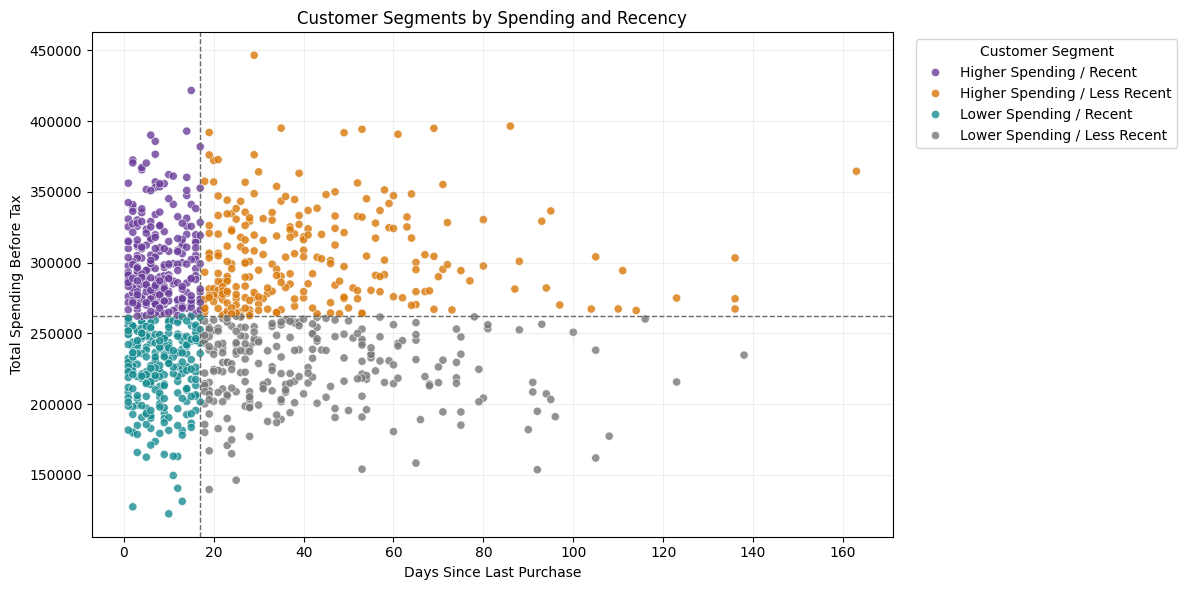

In [52]:
# Calculate thresholds using unrounded values
spending_threshold = customer_metrics["total_spending"].median()
recency_threshold = customer_metrics["recency_days"].median()

print(f"Total spending threshold: {spending_threshold:,.2f}")
print(f"Recency threshold: {recency_threshold:g} days")

# Define the two segmentation dimensions
higher_spending = (
    customer_metrics["total_spending"] >= spending_threshold
)
recent = (
    customer_metrics["recency_days"] <= recency_threshold
)

segment_order = [
    "Higher Spending / Recent",
    "Higher Spending / Less Recent",
    "Lower Spending / Recent",
    "Lower Spending / Less Recent"
]

# Assign every purchasing customer to one group
customer_metrics["customer_segment"] = np.select(
    [
        higher_spending & recent,
        higher_spending & ~recent,
        ~higher_spending & recent,
        ~higher_spending & ~recent
    ],
    segment_order,
    default="Unassigned"
)

# Display customer counts and shares
segment_counts = (
    customer_metrics["customer_segment"]
    .value_counts()
    .reindex(segment_order, fill_value=0)
    .to_frame("customer_count")
)

segment_counts["customer_share_pct"] = (
    segment_counts["customer_count"]
    / len(customer_metrics) * 100
)

display(
    segment_counts.style.format({
        "customer_count": "{:,.0f}",
        "customer_share_pct": "{:.2f}%"
    })
)

# Visualise the four groups
segment_colors = {
    segment_order[0]: "#6A3D9A",  # Higher Spending / Recent: purple
    segment_order[1]: "#D97706",  # Higher Spending / Less Recent: orange
    segment_order[2]: "#168C91",  # Lower Spending / Recent: teal
    segment_order[3]: "#777777"   # Lower Spending / Less Recent: grey
}


fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(
    data=customer_metrics,
    x="recency_days",
    y="total_spending",
    hue="customer_segment",
    hue_order=segment_order,
    palette=segment_colors,
    alpha=0.8,
    s=35,
    ax=ax
)

ax.axvline(
    recency_threshold,
    color="dimgray",
    linestyle="--",
    linewidth=1
)
ax.axhline(
    spending_threshold,
    color="dimgray",
    linestyle="--",
    linewidth=1
)

ax.set_title("Customer Segments by Spending and Recency")
ax.set_xlabel("Days Since Last Purchase")
ax.set_ylabel("Total Spending Before Tax")
ax.ticklabel_format(axis="y", style="plain")
ax.legend(
    title="Customer Segment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Observations**

---

The 1,000 purchasing customers are divided into four approximately
equal groups using median total spending of 262,188.80 and median
recency of 17 days. Recency is measured as of 2 January 2023.

- **Higher Spending / Recent contains 253 customers (25.30%)**.
  Their total spending is at or above the spending threshold,
  and their latest purchase is within 17 days of the reference date.
  This group combines higher historical spending with recent activity. Retention efforts should focus here to protect this core high-value active group.

- **Higher Spending / Less Recent contains 247 customers (24.70%)**.
  They have higher historical spending but last purchased more than
  17 days before the reference date. They may be considered for
  follow-up, although this classification does not establish churn risk.

- **Lower Spending / Recent contains 250 customers (25.00%)**.
  They purchased recently but have below-median total spending.
  Upselling and cross‑selling promotions can be tested to lift their spending.

- **Lower Spending / Less Recent contains 250 customers (25.00%)**.
  They have below-median spending and less recent purchases.
  These characteristics alone do not justify excluding them
  from marketing activity.

Since every purchasing customer has the same fixed order count of 50, segmentation relies only on recency and monetary value.

#### **4.3.3 Customer Segment Profiles and Sales Contribution**

Compare customer shares, sales contributions, average spending,
average order value and median recency across the four segments.

Sales differences between higher- and lower-spending groups are
expected because total spending is used to define the segments.

,customer_count,customer_share_pct,sales_revenue,sales_share_pct,average_spending,average_order_value,median_recency_days
customer_segment,,,,,,,
Higher Spending / Recent,253,25.30%,"76,202,720",28.90%,"301,197","6,024",7.0
Higher Spending / Less Recent,247,24.70%,"75,071,314",28.47%,"303,932","6,079",35.0
Lower Spending / Recent,250,25.00%,"56,046,882",21.25%,"224,188","4,484",8.0
Lower Spending / Less Recent,250,25.00%,"56,367,422",21.38%,"225,470","4,509",36.0


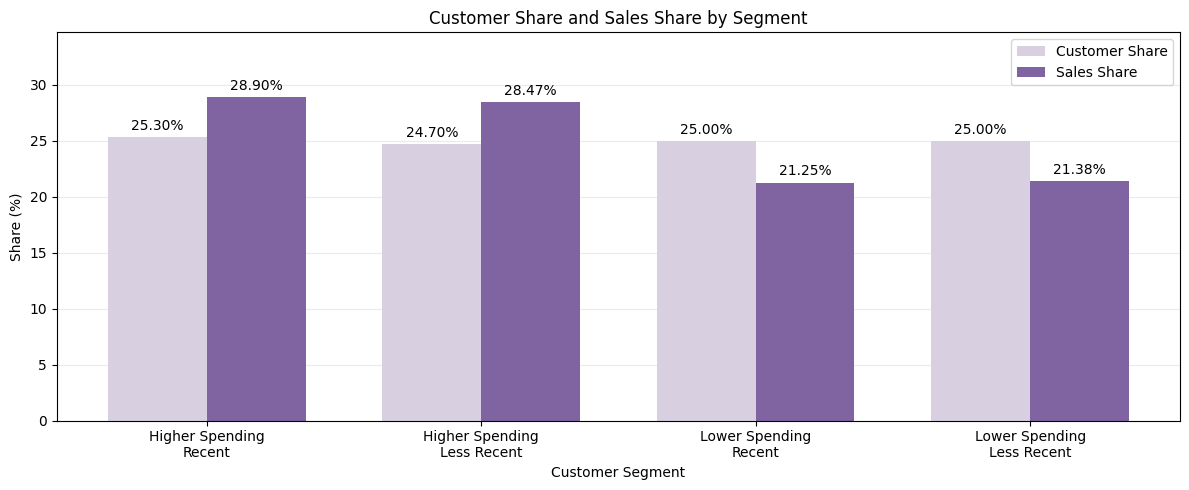

In [53]:
# Summarise customer segment profiles
segment_summary = (
    customer_metrics.groupby("customer_segment")
    .agg(
        customer_count=("customer_id", "nunique"),
        sales_revenue=("total_spending", "sum"),
        average_spending=("total_spending", "mean"),
        total_orders=("total_orders", "sum"),
        median_recency_days=("recency_days", "median")
    )
    .reindex(segment_order)
)

# Calculate segment AOV and contribution percentages
segment_summary["average_order_value"] = (
    segment_summary["sales_revenue"]
    / segment_summary["total_orders"]
)

segment_summary["customer_share_pct"] = (
    segment_summary["customer_count"]
    / segment_summary["customer_count"].sum() * 100
)

segment_summary["sales_share_pct"] = (
    segment_summary["sales_revenue"]
    / segment_summary["sales_revenue"].sum() * 100
)

# Arrange the table columns
segment_summary = segment_summary[
    [
        "customer_count",
        "customer_share_pct",
        "sales_revenue",
        "sales_share_pct",
        "average_spending",
        "average_order_value",
        "median_recency_days"
    ]
]

# Format table values
segment_formats = {
    column: "{:,.0f}"
    for column in segment_summary.columns
}
segment_formats["customer_share_pct"] = "{:.2f}%"
segment_formats["sales_share_pct"] = "{:.2f}%"
segment_formats["median_recency_days"] = "{:.1f}"

display(segment_summary.style.format(segment_formats))

# Compare customer share with sales share
short_labels = [
    "Higher Spending\nRecent",
    "Higher Spending\nLess Recent",
    "Lower Spending\nRecent",
    "Lower Spending\nLess Recent"
]

x = np.arange(len(segment_summary))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 5))

customer_bars = ax.bar(
    x - width / 2,
    segment_summary["customer_share_pct"],
    width,
    label="Customer Share",
    color="#D8D0E1"
)

sales_bars = ax.bar(
    x + width / 2,
    segment_summary["sales_share_pct"],
    width,
    label="Sales Share",
    color="#8064A2"
)

ax.bar_label(customer_bars, fmt="%.2f%%", padding=3)
ax.bar_label(sales_bars, fmt="%.2f%%", padding=3)

ax.set_title("Customer Share and Sales Share by Segment")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Share (%)")
ax.set_xticks(x)
ax.set_xticklabels(short_labels)

highest_share = segment_summary[
    ["customer_share_pct", "sales_share_pct"]
].max().max()

ax.set_ylim(0, highest_share * 1.2)
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Observations**

---



- The two higher-spending segments together represent 50% of
  purchasing customers and contribute approximately 57.37%
  of total sales.

- Higher Spending / Recent contributes the largest sales share
  at 28.90%, with median recency of 7 days. Higher Spending /
  Less Recent contributes 28.47%, with median recency of 35 days.

- Average spending and average order value are similar between
  the two higher-spending segments. Their main distinction is
  how recently customers last purchased, providing a basis
  for testing different engagement approaches.

- The two lower-spending segments each represent 25% of customers
  and contribute 21.25% and 21.38% of sales respectively.
  Their median recency is 8 days for Recent customers and
  36 days for Less Recent customers.

- Less Recent customers have longer gaps since their last purchase,
  but this does not by itself establish inactivity or churn risk.

#### **4.3.4 Objective 3: Summary of Key Findings**

Customers are segmented using total spending and recency. Order count is excluded because every purchasing customer has placed exactly 50 orders. Average order value produces the same customer ranking as total spending.

The two higher-spending segments represent 50% of purchasing customers and contribute approximately 57.37% of total sales. Higher Spending / Recent contributes 28.90%, while Higher Spending / Less Recent contributes 28.47%. Their median recency is 7 days and 35 days respectively, as of 2 January 2023.

These groups separate higher historical sales contributors based on their recent purchase activity. Retention offers could be tested for higher-spending recent buyers, follow-up re‑engagement messages for higher-spending less recent buyers, and relevant cross-selling offers for lower-spending recent buyers.

These median-based groups describe historical behaviour rather than predict customer loyalty or churn. Campaign effectiveness should be evaluated through subsequent testing.

### **4.4 Objective 4: Product Performance and Revenue Concentration**

Evaluate product performance using sales revenue, units sold,
order counts and purchasing customer counts to support
product portfolio decisions.



#### **4.4.1 Product Sales Revenue and Volume**

Compare all product groups by sales revenue and units sold.
Calculate average realised selling price to distinguish
sales value from sales volume.

,sales_revenue,units_sold,total_orders,purchasing_customers,average_selling_price,sales_share_pct
product_category,,,,,,
Home & Living,"177,313,524","91,700","16,617","1,000","1,934",67.24%
Electronics,"75,410,755","91,514","16,749","1,000",824,28.60%
Fashion & Apparel,"10,964,060","91,664","16,634","1,000",120,4.16%


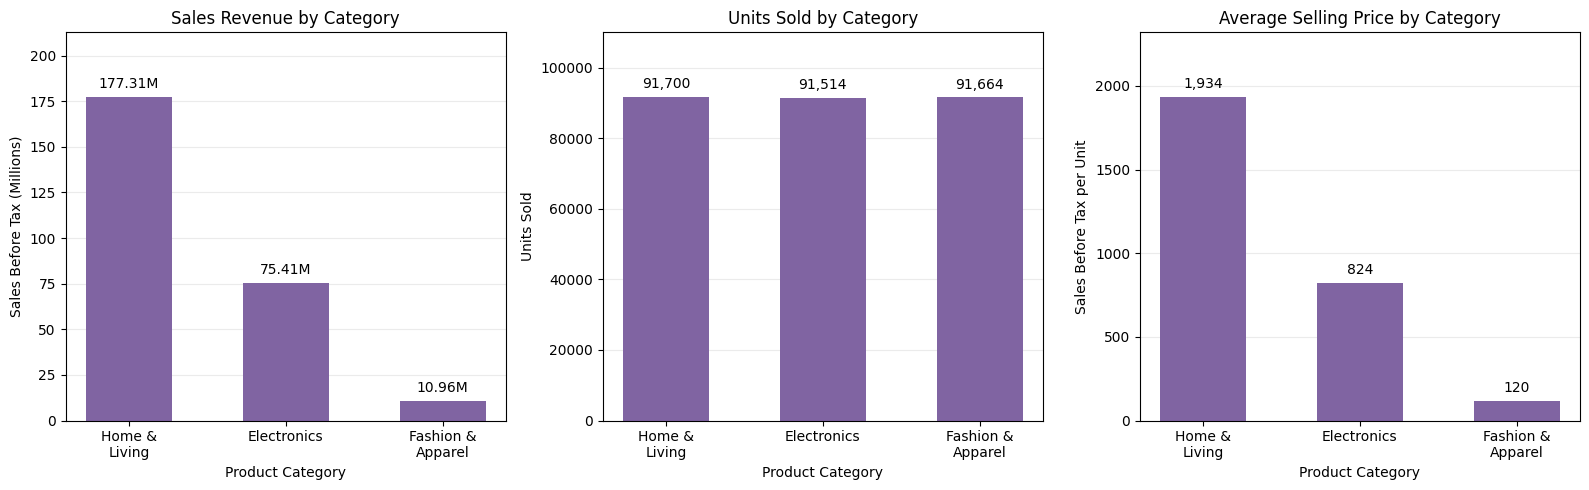

In [22]:
# Summarise performance by product category
category_summary = (
    retail_data.groupby("product_category")
    .agg(
        sales_revenue=("sales_before_tax", "sum"),
        units_sold=("quantity", "sum"),
        total_orders=("order_id", "nunique"),
        purchasing_customers=("customer_id", "nunique")
    )
    .sort_values("sales_revenue", ascending=False)
)

# Calculate average selling price after discount, before tax
category_summary["average_selling_price"] = (
    category_summary["sales_revenue"]
    / category_summary["units_sold"]
)

# Calculate sales contribution
category_summary["sales_share_pct"] = (
    category_summary["sales_revenue"]
    / category_summary["sales_revenue"].sum() * 100
)

# Display the summary table
category_formats = {
    column: "{:,.0f}"
    for column in category_summary.columns
}
category_formats["sales_share_pct"] = "{:.2f}%"

display(category_summary.style.format(category_formats))

# Plot revenue, units sold and average selling price
metrics = [
    (
        "sales_revenue",
        "Sales Revenue by Category",
        "Sales Before Tax (Millions)",
        1_000_000
    ),
    (
        "units_sold",
        "Units Sold by Category",
        "Units Sold",
        1
    ),
    (
        "average_selling_price",
        "Average Selling Price by Category",
        "Sales Before Tax per Unit",
        1
    )
]

category_labels = [
    label.replace(" & ", " &\n")
    for label in category_summary.index
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (column, title, ylabel, divisor) in zip(axes, metrics):
    values = category_summary[column] / divisor

    bars = ax.bar(
        category_labels,
        values,
        color="#8064A2",
        width=0.55
    )

    labels = [
        f"{value:.2f}M" if divisor == 1_000_000
        else f"{value:,.0f}"
        for value in values
    ]

    ax.bar_label(bars, labels=labels, padding=4)
    ax.set_title(title)
    ax.set_xlabel("Product Category")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, values.max() * 1.2)
    ax.ticklabel_format(axis="y", style="plain")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Observations**

---



- Home & Living generates the highest sales revenue at
  177.31 million, contributing 67.24% of total sales.
  Electronics contributes 75.41 million (28.60%), while
  Fashion & Apparel contributes 10.96 million (4.16%).

- Units sold are nearly identical across categories, ranging
  from 91,514 to 91,700. Total order counts are also similar.

- Average realised selling price differs substantially:
  approximately 1,934 for Home & Living, 824 for Electronics,
  and 120 for Fashion & Apparel. Revenue differences mainly
  reflect selling prices rather than differences in sales volume.

- All 1,000 purchasing customers have bought from each category.
  Customer counts therefore do not distinguish category reach
  within this dataset.

- Home & Living is the main revenue contributor, but lower
  revenue does not imply weaker demand or lower profitability.
  Product decisions should consider sales volume alongside
  revenue, with cost and inventory data needed for further assessment.

#### **4.4.2 Product Rankings by Revenue and Volume**

Identify the five highest- and lowest-revenue product types,
and the five best-selling product types by units sold.

Revenue rankings are interpreted alongside sales volume and
average realised selling price.

Top 5 Products by Sales Revenue


,sales_revenue,units_sold,total_orders,purchasing_customers,average_selling_price,sales_share_pct
product_name,,,,,,
Curtains,"18,622,538","9,329","1,695",812,"1,996",7.06%
Wall Art,"18,233,601","9,443","1,707",819,"1,931",6.91%
Lighting,"17,948,346","8,954","1,652",810,"2,005",6.81%
Furniture,"17,908,208","9,442","1,695",815,"1,897",6.79%
Kitchen Appliances,"17,737,327","9,148","1,666",807,"1,939",6.73%


Bottom 5 Products by Sales Revenue


,sales_revenue,units_sold,total_orders,purchasing_customers,average_selling_price,sales_share_pct
product_name,,,,,,
Dress,"1,028,147","8,709","1,578",824,118,0.39%
Skirt,"1,040,820","8,732","1,602",780,119,0.39%
Shoes,"1,063,620","8,665","1,588",798,123,0.40%
Formal Shirt,"1,072,821","9,084","1,639",812,118,0.41%
Sweater,"1,095,549","9,057","1,664",823,121,0.42%


Top 5 Products by Units Sold


,sales_revenue,units_sold,total_orders,purchasing_customers,average_selling_price,sales_share_pct
product_name,,,,,,
Sports Shoes,"1,156,007","9,642","1,763",838,120,0.44%
Jeans,"1,129,295","9,524","1,692",817,119,0.43%
Jacket,"1,155,103","9,503","1,686",810,122,0.44%
Wireless Speaker,"7,755,158","9,457","1,717",810,820,2.94%
Wall Art,"18,233,601","9,443","1,707",819,"1,931",6.91%


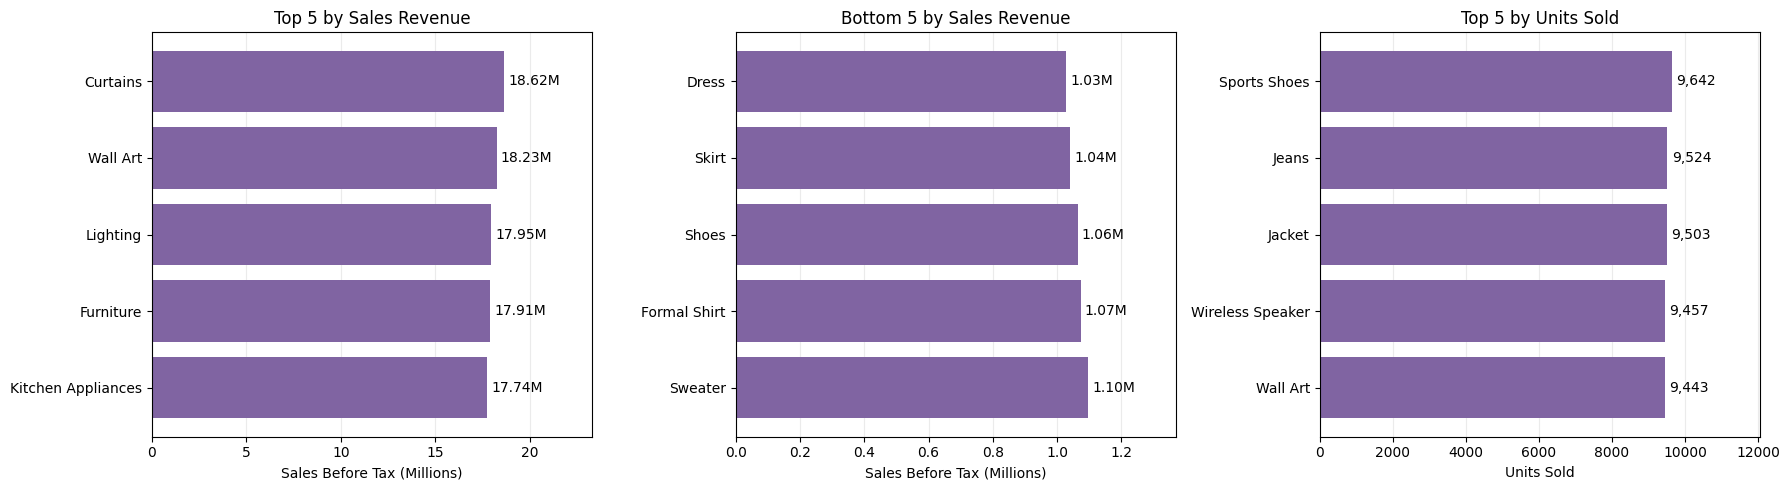

In [23]:
# Summarise individual product performance
product_summary = (
    retail_data.groupby("product_name")
    .agg(
        sales_revenue=("sales_before_tax", "sum"),
        units_sold=("quantity", "sum"),
        total_orders=("order_id", "nunique"),
        purchasing_customers=("customer_id", "nunique")
    )
)

product_summary["average_selling_price"] = (
    product_summary["sales_revenue"]
    / product_summary["units_sold"]
)

product_summary["sales_share_pct"] = (
    product_summary["sales_revenue"]
    / product_summary["sales_revenue"].sum() * 100
)

product_summary = product_summary.sort_values(
    "sales_revenue", ascending=False
)

# Select products for comparison
top_revenue = product_summary.head(5)
bottom_revenue = product_summary.tail(5).sort_values(
    "sales_revenue"
)
top_volume = product_summary.sort_values(
    "units_sold", ascending=False
).head(5)

# Display supporting tables
product_formats = {
    column: "{:,.0f}"
    for column in product_summary.columns
}
product_formats["sales_share_pct"] = "{:.2f}%"

for title, table in [
    ("Top 5 Products by Sales Revenue", top_revenue),
    ("Bottom 5 Products by Sales Revenue", bottom_revenue),
    ("Top 5 Products by Units Sold", top_volume)
]:
    print(title)
    display(table.style.format(product_formats))

# Plot product rankings
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

charts = [
    (
        top_revenue,
        "sales_revenue",
        "Top 5 by Sales Revenue",
        "Sales Before Tax (Millions)",
        1_000_000
    ),
    (
        bottom_revenue,
        "sales_revenue",
        "Bottom 5 by Sales Revenue",
        "Sales Before Tax (Millions)",
        1_000_000
    ),
    (
        top_volume,
        "units_sold",
        "Top 5 by Units Sold",
        "Units Sold",
        1
    )
]

for ax, (table, column, title, xlabel, divisor) in zip(
    axes, charts
):
    values = table[column] / divisor

    bars = ax.barh(
        table.index,
        values,
        color="#8064A2"
    )

    labels = [
        f"{value:.2f}M" if divisor == 1_000_000
        else f"{value:,.0f}"
        for value in values
    ]

    ax.bar_label(bars, labels=labels, padding=3)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.set_xlim(0, values.max() * 1.25)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Observations**

---



- Curtains generates the highest sales revenue at 18.62 million,
  followed by Wall Art, Lighting, Furniture and Kitchen Appliances.
  All five belong to Home & Living.

- Dress records the lowest sales revenue at approximately
  1.03 million, followed by Skirt, Shoes, Formal Shirt and Sweater.
  All five belong to Fashion & Apparel and have average realised
  selling prices of approximately 118–123 per unit.

- Sports Shoes leads sales volume with 9,642 units sold, followed
  by Jeans and Jacket. Despite their high volume rankings,
  each contributes less than 0.5% of total sales.

- Wall Art appears in both the top-five revenue and volume rankings,
  combining relatively high unit sales with a higher selling price.

- Revenue and volume rankings highlight different aspects of
  product performance. Lower-revenue products should not be
  removed solely on this basis; margins, inventory turnover
  and their role in customer purchases require further assessment.

#### **4.4.3 Cumulative Revenue Contribution**

Rank product types by sales revenue and calculate their cumulative
sales contribution. Identify how many product types account for
at least 80% of total sales, without assuming an 80/20 distribution.

Product types needed to reach at least 80% of sales: 15 out of 30
Their cumulative sales contribution: 81.80%
Top 5 sales contribution: 34.30%
Top 10 sales contribution: 67.24%


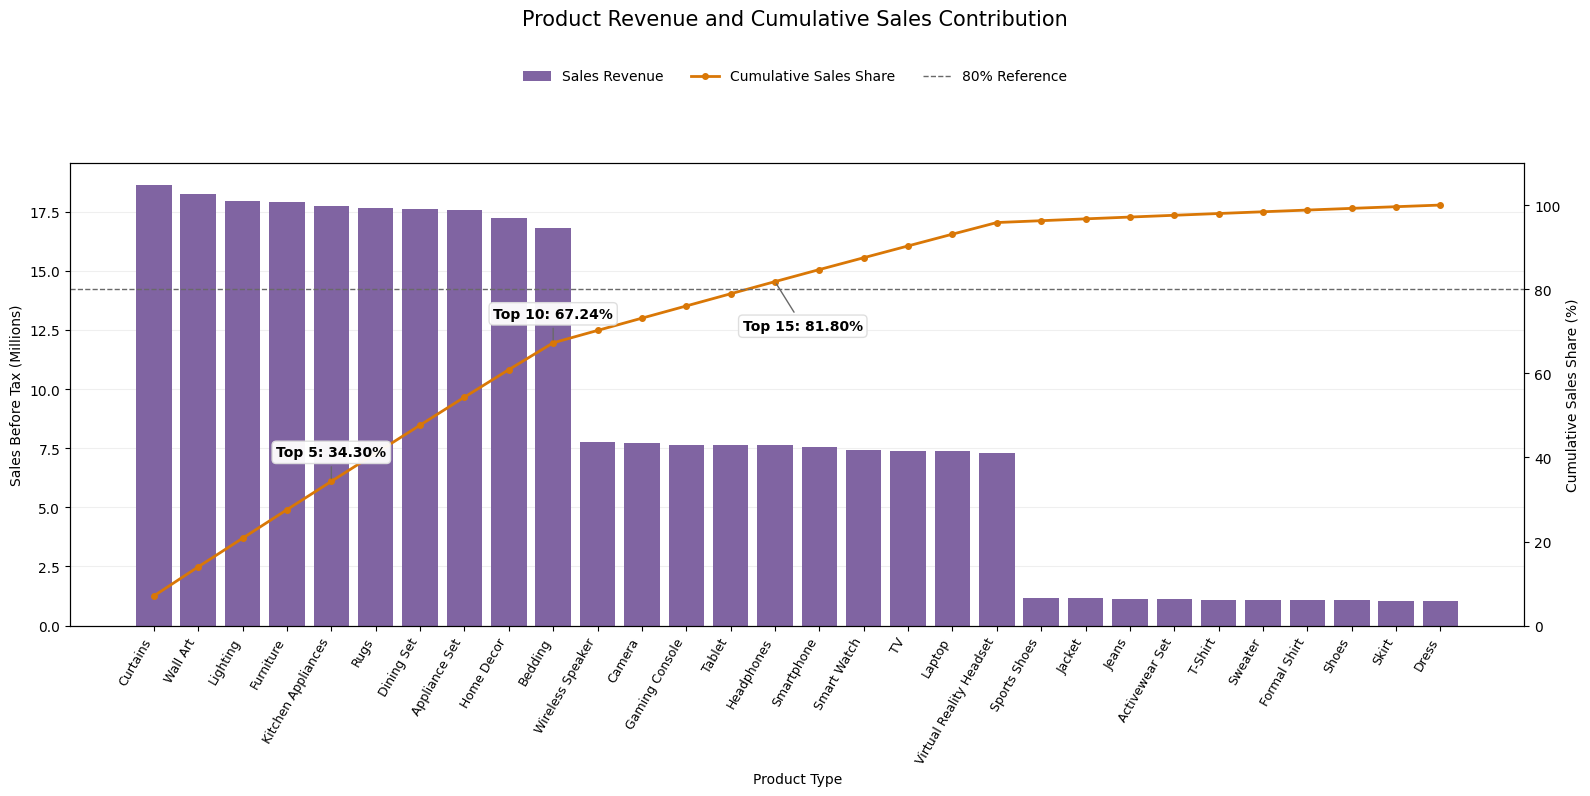

In [24]:
# Rank products and calculate cumulative revenue contribution
pareto_data = product_summary.sort_values(
    "sales_revenue", ascending=False
).copy()

pareto_data["sales_share_pct"] = (
    pareto_data["sales_revenue"]
    / pareto_data["sales_revenue"].sum() * 100
)

pareto_data["cumulative_sales_pct"] = (
    pareto_data["sales_share_pct"].cumsum()
)

# Find the number of products needed to reach at least 80%
products_to_80 = (
    np.flatnonzero(
        pareto_data["cumulative_sales_pct"].to_numpy() >= 80
    )[0] + 1
)

print(
    f"Product types needed to reach at least 80% of sales: "
    f"{products_to_80} out of {len(pareto_data)}"
)
print(
    f"Their cumulative sales contribution: "
    f"{pareto_data['cumulative_sales_pct'].iloc[products_to_80 - 1]:.2f}%"
)
print(
    f"Top 5 sales contribution: "
    f"{pareto_data['sales_share_pct'].head(5).sum():.2f}%"
)
print(
    f"Top 10 sales contribution: "
    f"{pareto_data['sales_share_pct'].head(10).sum():.2f}%"
)

# Plot revenue bars and cumulative contribution
x = np.arange(len(pareto_data))

fig, ax1 = plt.subplots(figsize=(16,8))

ax1.bar(
    x,
    pareto_data["sales_revenue"] / 1_000_000,
    color="#8064A2",
    label="Sales Revenue"
)

ax1.set_xlabel("Product Type")
ax1.set_ylabel("Sales Before Tax (Millions)")
ax1.set_xticks(x)
ax1.set_xticklabels(
    pareto_data.index,
    rotation=60,
    ha="right",
    fontsize=9
)
ax1.grid(axis="y", alpha=0.2)
ax1.set_axisbelow(True)

# Secondary axis for cumulative sales share
ax2 = ax1.twinx()

ax2.plot(
    x,
    pareto_data["cumulative_sales_pct"],
    color="#D97706",
    marker="o",
    markersize=4,
    linewidth=2,
    label="Cumulative Sales Share"
)

ax2.axhline(
    80,
    color="dimgray",
    linestyle="--",
    linewidth=1,
    label="80% Reference"
)

ax2.set_ylabel("Cumulative Sales Share (%)")
ax2.set_ylim(0, 110)

# Label only the key cumulative milestones
for number, offset in [
    (5, (0, 18)),
    (10, (0, 18)),
    (products_to_80, (20, -35))
]:
    position = number - 1
    percentage = pareto_data[
        "cumulative_sales_pct"
    ].iloc[position]

    ax2.annotate(
        f"Top {number}: {percentage:.2f}%",
        xy=(position, percentage),
        xytext=offset,
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        bbox={
            "boxstyle": "round,pad=0.3",
            "facecolor": "white",
            "edgecolor": "#DDDDDD",
            "alpha": 0.95
        },
        arrowprops={
            "arrowstyle": "-",
            "color": "dimgray"
        }
    )

# Place the legend above the chart
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

fig.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Product Revenue and Cumulative Sales Contribution",
    fontsize=15,
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

**Observations**

---



- The Pareto chart ranks 30 product types by sales revenue.
  The top five contribute 34.30% of total sales, while the
  top ten contribute 67.24%.

- Fifteen out of thirty product types contribute 81.80% of sales,
  crossing the 80% reference line. Therefore, 50% of product types
  are needed to generate approximately 80% of sales, rather than 20%.

- The remaining 15 product types contribute 18.20% of total sales.
  The ten highest-revenue product types all belong to Home & Living,
  highlighting revenue concentration within this category.

- Higher-revenue products warrant close sales monitoring, but revenue
  alone cannot establish profitability or justify inventory allocation.
  Margins, inventory holding costs and demand stability should also
  inform product portfolio decisions.



#### **4.4.4 Objective 4: Summary of Key Findings**

Home & Living is the main revenue contributor, generating 177.31 million and accounting for 67.24% of total sales. Sales volumes are nearly identical across the three categories, so revenue differences mainly reflect variations in average realised selling prices.

Curtains generates the highest product revenue, while Sports Shoes records the highest units sold. This shows that revenue rankings and volume rankings capture different dimensions of product performance.

The top ten product types contribute 67.24% of sales, and fifteen out of the thirty product types contribute 81.80%. Revenue is concentrated within Home & Living.

Product decisions should consider revenue, quantities sold and selling prices together. Home & Living warrants close monitoring given its substantial revenue contribution. Lower-revenue products should be evaluated using profit margins, inventory turnover and customer purchasing patterns before any reduction to product range or stock allocation.





### **4.5 Objective 5: Discount and Purchasing Behaviour Analysis**

Examine relationships between discount rates, quantities purchased
and sales before tax to support promotional planning.

The analysis describes associations and does not establish that
discounts cause changes in purchasing behaviour.



#### **4.5.1 Purchasing Behaviour by Discount Band**

Group orders into six discount bands: No Discount (0%), 1–10%, 11–20%, 21–30%, 31–40%, and 41–50%.

Compare order counts, average quantity per order and average order
value. Differences in product mix and prices may affect these results.

Orders without a discount band: 0


,total_orders,units_sold,sales_revenue,average_unit_price,average_quantity_per_order,average_order_value
discount_band,,,,,,
No Discount,477,"2,729","3,709,979","1,335",5.72,"7,778"
1–10%,"10,135","55,726","67,811,030","1,280",5.50,"6,691"
11–20%,"10,012","54,999","59,134,804","1,267",5.49,"5,906"
21–30%,"9,943","54,708","51,523,889","1,275",5.50,"5,182"
31–40%,"10,025","55,114","45,024,783","1,270",5.50,"4,491"
41–50%,"9,408","51,602","36,483,855","1,285",5.48,"3,878"


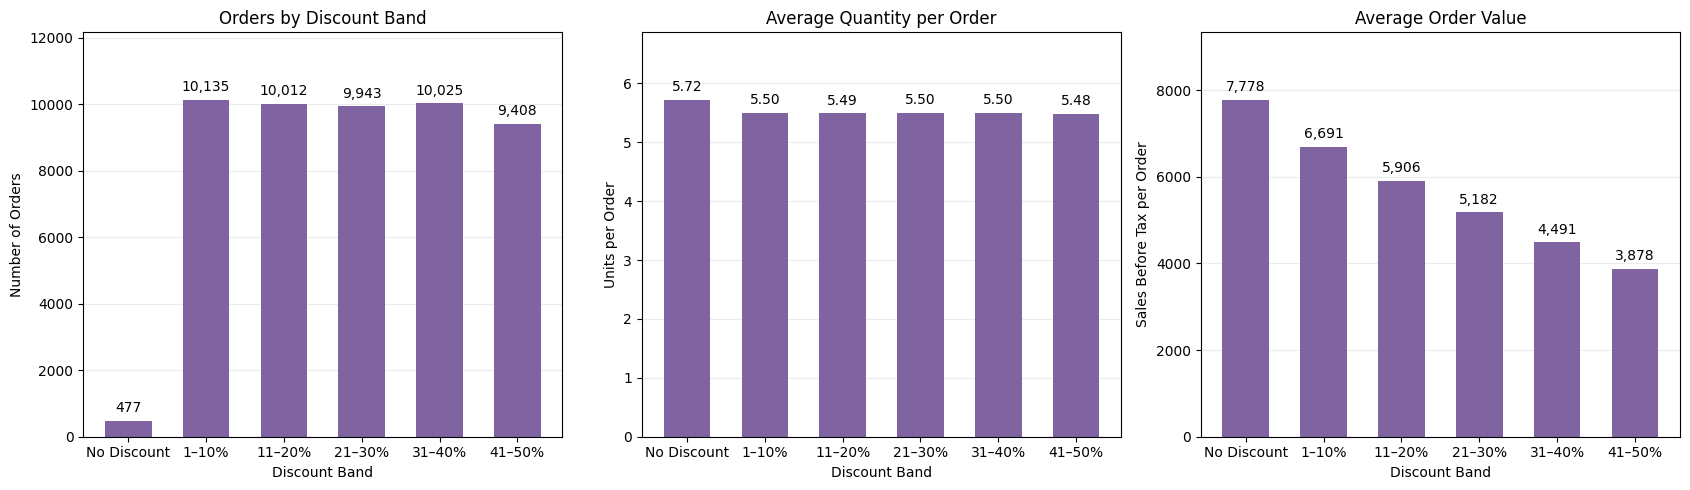

In [25]:
# Create discount bands: upper boundary included.
# Separate orders with no discount
discount_bins = [-0.001, 0, 0.10, 0.20, 0.30, 0.40, 0.50]

discount_labels = [
    "No Discount",
    "1–10%",
    "11–20%",
    "21–30%",
    "31–40%",
    "41–50%"
]

retail_data["discount_band"] = pd.cut(
    retail_data["discount"],
    bins=discount_bins,
    labels=discount_labels,
    right=True
)

# Check that every order has a discount band
print(
    "Orders without a discount band:",
    retail_data["discount_band"].isna().sum()
)

# Summarise purchasing behaviour
discount_summary = (
    retail_data.groupby("discount_band", observed=True)
    .agg(
        total_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        sales_revenue=("sales_before_tax", "sum"),
        average_unit_price=("price", "mean")
    )
    .sort_index()
)

discount_summary["average_quantity_per_order"] = (
    discount_summary["units_sold"]
    / discount_summary["total_orders"]
)

discount_summary["average_order_value"] = (
    discount_summary["sales_revenue"]
    / discount_summary["total_orders"]
)

# Display the summary table
discount_formats = {
    column: "{:,.0f}"
    for column in discount_summary.columns
}
discount_formats["average_quantity_per_order"] = "{:.2f}"

display(discount_summary.style.format(discount_formats))

# Plot order counts, quantity per order and AOV
metrics = [
    ("total_orders", "Orders by Discount Band",
     "Number of Orders", "{:,.0f}"),
    ("average_quantity_per_order", "Average Quantity per Order",
     "Units per Order", "{:.2f}"),
    ("average_order_value", "Average Order Value",
     "Sales Before Tax per Order", "{:,.0f}")
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (column, title, ylabel, number_format) in zip(
    axes, metrics
):
    values = discount_summary[column]

    bars = ax.bar(
        discount_summary.index.astype(str),
        values,
        color="#8064A2",
        width=0.6
    )

    ax.bar_label(
        bars,
        labels=[number_format.format(value) for value in values],
        padding=4
    )

    ax.set_title(title)
    ax.set_xlabel("Discount Band")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, values.max() * 1.2)
    ax.tick_params(axis="x")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Observations**

---


- Orders are distributed across six discount bands. Only 477 orders have no discount. Among discounted orders, counts remain broadly similar from the 1–10% to the 31–40% band, before falling slightly at 41–50%. These counts alone do not demonstrate that discounts attract more orders.
- Average quantity per order remains similar across discounted bands at 5.48–5.50 units, compared with 5.72 units for orders without a discount. Higher discount levels are not associated with noticeably larger quantities purchased per order.
- Average order value decreases steadily from 7,778 for orders without a discount to 3,878 in the 41–50% band. Average original unit prices remain relatively similar across discounted bands. The decline is consistent with discounts directly reducing calculated sales revenue, although product mix may also influence the results.
- These patterns do not establish whether discounts generate additional demand or improve profitability. Evaluating their effectiveness would require comparable baseline sales or controlled campaign testing, alongside cost and margin data.

#### **4.5.2 Discount and Purchase Quantity by Product**

Use a heatmap to compare average quantity per order across discount bands for each product type. Read across each row to assess whether higher discounts are associated with larger purchase quantities for the same product type.

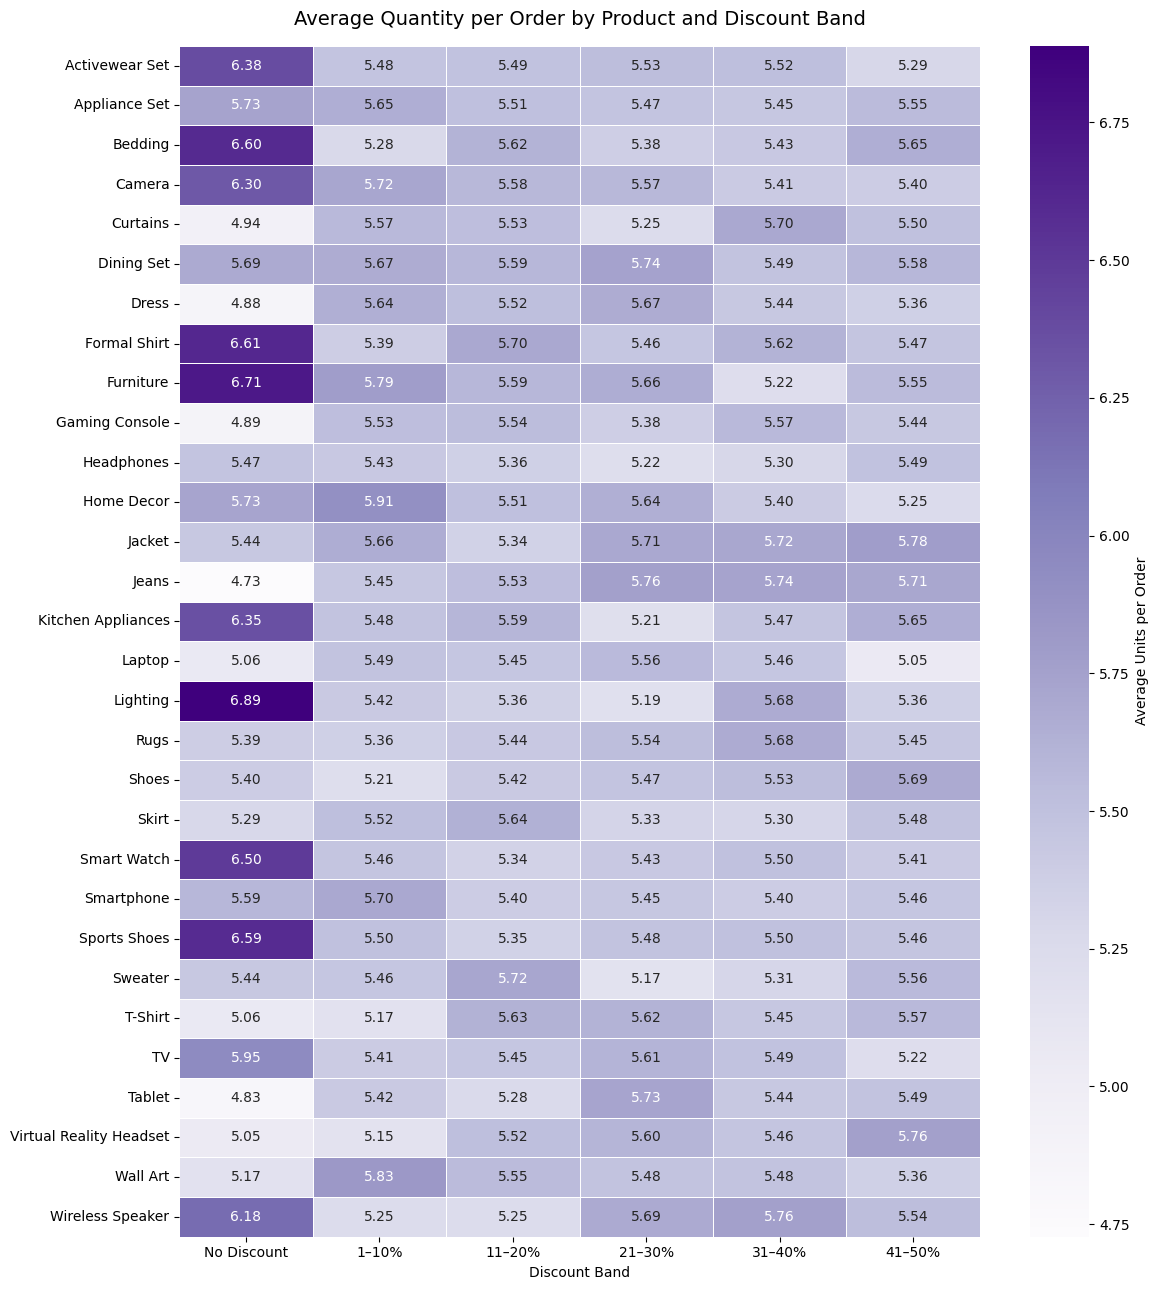

In [26]:
# Calculate average quantity per order
discount_order = [
    "No Discount", "1–10%", "11–20%",
    "21–30%", "31–40%", "41–50%"
]

# Each row represents one order
quantity_by_discount = (
    retail_data.pivot_table(
        index="product_name",
        columns="discount_band",
        values="quantity",
        aggfunc="mean",
        observed=True
    )
    .reindex(columns=discount_order)
    .sort_index()
)

# Plot the heatmap
fig, ax = plt.subplots(figsize=(12, 13))

sns.heatmap(
    quantity_by_discount,
    annot=True,
    fmt=".2f",
    cmap="Purples",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Average Units per Order"},
    ax=ax
)

ax.set_title(
    "Average Quantity per Order by Product and Discount Band",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Discount Band")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

**Observations**

---


- For most product types, average quantity per order fluctuates across discount bands without a consistent upward trend.
- Lighting, Furniture, Activewear Set and Smart Watch record their highest average quantities in the No Discount group. Across discounted bands, their purchase quantities fluctuate without a consistent upward trend.
- Patterns differ across products. Shoes increases steadily from 5.21 units in the 1–10% band to 5.69 units in the 41–50% band, while Camera decreases from 5.72 to 5.40 units across the same bands.
- Overall, higher discounts are not consistently associated with larger quantities purchased per order. Controlled testing would be needed to establish additional demand, while cost and margin data would also be needed to assess profitability.

#### **4.5.3 Objective 5: Summary of Key Findings**
Most recorded orders include a discount. Across discounted bands, average quantity per order remains nearly constant at 5.48–5.50 units, while average order value decreases from 6,691 in the 1–10% band to 3,878 in the 41–50% band. This decline partly reflects discounts directly reducing calculated sales revenue.

Product-level analysis shows no consistent increase in average purchase quantity as discounts rise. Patterns differ between products: Shoes records increasing quantities across discounted bands, while Camera shows a decreasing pattern.

Overall, higher discounts are not consistently associated with larger quantities purchased per order. These results cannot establish whether discounts generate additional orders or improve profitability. Before expanding discounts, the company should test targeted promotions against a comparable control group, tracking additional sales, repeat purchases and profit margins.

## **5. Data Export for Power BI**

Export the prepared transaction and customer datasets for Power BI.

In [27]:
# Prepare customer data with segmentation results
customers_export = customers_clean.merge(
    customer_metrics[[
        "customer_id",
        "total_spending",
        "total_orders",
        "average_order_value",
        "last_purchase_date",
        "recency_days",
        "customer_segment"
    ]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Label customers without recorded purchases
customers_export["customer_segment"] = (
    customers_export["customer_segment"]
    .astype("string")
    .fillna("No Recorded Purchases")
)

# Fill spending and order counts for non-purchasing customers
customers_export[["total_spending", "total_orders"]] = (
    customers_export[["total_spending", "total_orders"]]
    .fillna(0)
)

# Export CSV files without a dataframe index
retail_data.to_csv(
    "retail_transactions.csv",
    index=False,
    date_format="%Y-%m-%d",
    encoding="utf-8-sig"
)

customers_export.to_csv(
    "retail_customers.csv",
    index=False,
    date_format="%Y-%m-%d",
    encoding="utf-8-sig"
)

print(f"Transaction records exported: {len(retail_data):,}")
print(f"Customer records exported: {len(customers_export):,}")

# Download files from Google Colab
from google.colab import files

files.download("retail_transactions.csv")
files.download("retail_customers.csv")

Transaction records exported: 50,000
Customer records exported: 1,001


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **6. Sales Forecasting**

### **6.1 Forecasting Objective and Data Preparation**

Forecast total sales before tax for January 2023 using historical
monthly sales.

Only complete months from September 2019 to December 2022 are
included. August 2019 and January 2023 are excluded because they
contain partial-month data.

The data is split chronologically into 80% for training and 20%
for testing. The final eight complete months are reserved for testing.

In [28]:
# Prepare a separate dataset for forecasting
forecast_data = retail_data.copy()

# Ensure order dates are in datetime format
forecast_data["order_date"] = pd.to_datetime(
    forecast_data["order_date"],
    errors="raise"
)

# Include complete months only: September 2019–December 2022
forecast_data = forecast_data.loc[
    (forecast_data["order_date"] >= "2019-09-01")
    & (forecast_data["order_date"] < "2023-01-01")
].copy()

# Calculate monthly sales before tax
monthly_revenue = (
    forecast_data
    .set_index("order_date")["sales_before_tax"]
    .resample("MS")
    .sum(min_count=1)
    .asfreq("MS")
)

# Check for months without sales records
assert monthly_revenue.notna().all(), \
    "Some months have no sales records. Investigate before modelling."

# Split chronologically: 80% training, 20% testing
split_position = int(len(monthly_revenue) * 0.8)

train_sales = monthly_revenue.iloc[:split_position]
test_sales = monthly_revenue.iloc[split_position:]

# Summarise the training and testing datasets
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Months": [len(train_sales), len(test_sales)],
    "Percentage": [
        len(train_sales) / len(monthly_revenue) * 100,
        len(test_sales) / len(monthly_revenue) * 100
    ],
    "Start": [
        train_sales.index.min().strftime("%Y-%m"),
        test_sales.index.min().strftime("%Y-%m")
    ],
    "End": [
        train_sales.index.max().strftime("%Y-%m"),
        test_sales.index.max().strftime("%Y-%m")
    ]
})

display(
    split_summary.style.format({
        "Months": "{:.0f}",
        "Percentage": "{:.0f}%"
    }).hide(axis="index")
)

Dataset,Months,Percentage,Start,End
Training,32,80%,2019-09,2022-04
Testing,8,20%,2022-05,2022-12


### **6.2 Baseline and Forecast Model**

A simple linear regression model is used to predict monthly sales
before tax using a sequential month index.

The first 80% of complete months are used for training, and the
remaining 20% are reserved for testing. The chronological order
is preserved to avoid using future observations to predict the past.

A historical mean baseline is included to assess whether linear
regression improves on a simple constant forecast.

In [54]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Create one record per complete month
model_data = monthly_revenue.rename("sales_before_tax").to_frame()

# September 2019 = 0, October 2019 = 1, and so on
model_data["month_index"] = np.arange(len(model_data))

# Define input feature and prediction target
X = model_data[["month_index"]]
y = model_data["sales_before_tax"]

# Split chronologically: 80% training, 20% testing
split_position = int(len(model_data) * 0.8)

X_train = X.iloc[:split_position]
X_test = X.iloc[split_position:]

y_train = y.iloc[:split_position]
y_test = y.iloc[split_position:]

# Train the linear regression model
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predict the test period
y_pred = lr.predict(X_test)

# Historical mean baseline: training data only
baseline_pred = np.full(len(y_test), y_train.mean())

# Compare actual and predicted sales
prediction_comparison = pd.DataFrame({
    "Actual Sales": y_test,
    "Linear Regression": y_pred,
    "Historical Mean": baseline_pred
})

display(
    prediction_comparison.style
    .format("{:,.0f}")
    .format_index(lambda date: date.strftime("%Y-%m"), axis=0)
)

,Actual Sales,Linear Regression,Historical Mean
order_date,,,
2022-05,"7,307,882","6,265,772","6,483,754"
2022-06,"6,111,676","6,252,561","6,483,754"
2022-07,"6,386,286","6,239,350","6,483,754"
2022-08,"6,661,843","6,226,139","6,483,754"
2022-09,"6,262,907","6,212,928","6,483,754"
2022-10,"6,633,499","6,199,717","6,483,754"
2022-11,"6,681,530","6,186,506","6,483,754"
2022-12,"6,452,515","6,173,295","6,483,754"


### **6.3 Model Evaluation**

Test predictions are compared with actual monthly sales using
R², MSE, RMSE and MAE.

R² measures performance relative to predicting the test-set mean.
A negative R² indicates that the model performs worse than that
reference. Lower error values indicate better predictive performance.

The historical mean baseline uses the training-period average only.

,R²,MSE,RMSE,MAE
Linear Regression,-0.988,"228,868,199,553","478,402","377,955"
Historical Mean,-0.054,"121,266,509,022","348,233","258,921"


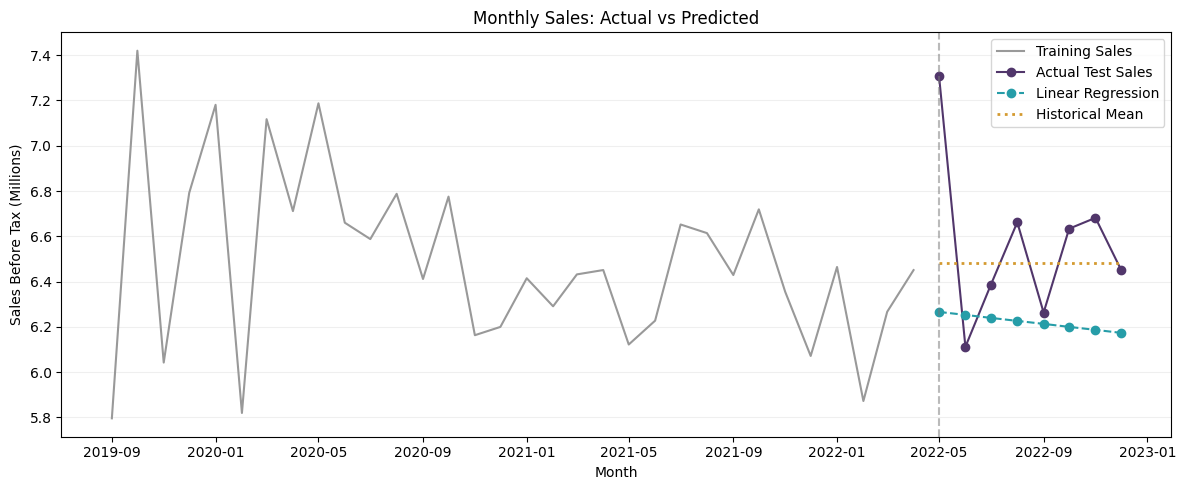

In [55]:
# Evaluate both methods on the same test months
evaluation = pd.DataFrame({
    name: {
        "R²": r2_score(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "MAE": mean_absolute_error(y_test, predictions)
    }
    for name, predictions in {
        "Linear Regression": y_pred,
        "Historical Mean": baseline_pred
    }.items()
}).T

display(
    evaluation.style.format({
        "R²": "{:.3f}",
        "MSE": "{:,.0f}",
        "RMSE": "{:,.0f}",
        "MAE": "{:,.0f}"
    })
)

# Plot actual and predicted sales
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    y_train.index,
    y_train / 1_000_000,
    color="#999999",
    label="Training Sales"
)

ax.plot(
    y_test.index,
    y_test / 1_000_000,
    color="#51366B",
    marker="o",
    label="Actual Test Sales"
)

ax.plot(
    y_test.index,
    y_pred / 1_000_000,
    color="#269DA8",
    marker="o",
    linestyle="--",
    label="Linear Regression"
)

ax.plot(
    y_test.index,
    baseline_pred / 1_000_000,
    color="#D49A30",
    linestyle=":",
    linewidth=2,
    label="Historical Mean"
)

ax.axvline(
    y_test.index[0],
    color="#777777",
    linestyle="--",
    alpha=0.5
)

ax.set_title("Monthly Sales: Actual vs Predicted")
ax.set_xlabel("Month")
ax.set_ylabel("Sales Before Tax (Millions)")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

### **6.4 January 2023 Sales Forecast**

After evaluating the model, linear regression is refitted using
all 40 complete months from September 2019 to December 2022.

The fitted model is then used to forecast January 2023 sales
before tax. This forecast extrapolates the estimated linear
time trend and does not explicitly model seasonality.

Forecast Month,Method,Forecast Sales Before Tax
January 2023,Linear Regression,"6,394,119"


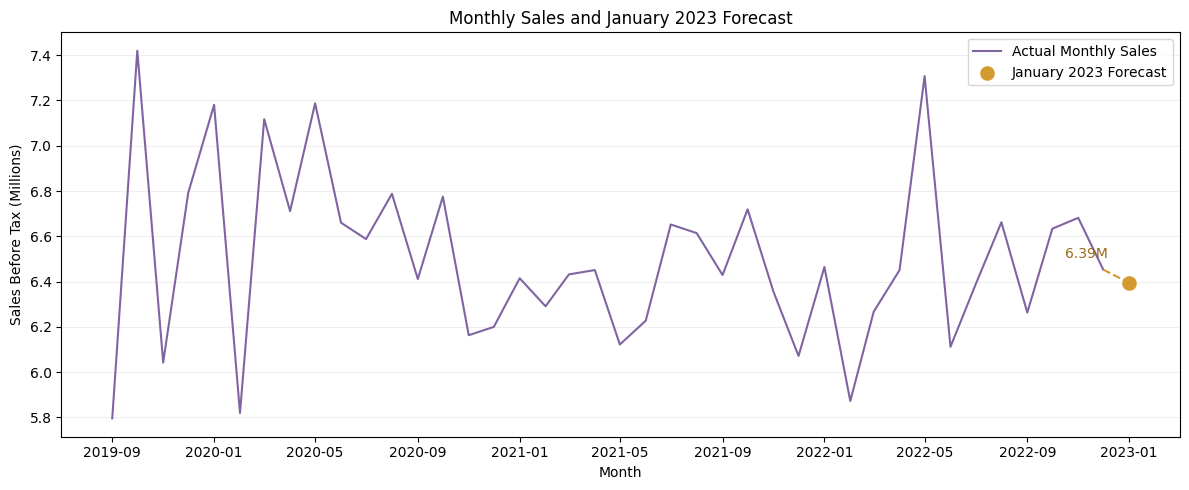

In [56]:
# Refit linear regression using all complete months
final_model = LinearRegression()
final_model.fit(X, y)

# Predict the next month: January 2023
future_X = pd.DataFrame({
    "month_index": [len(model_data)]
})

january_forecast = final_model.predict(future_X)[0]
forecast_month = monthly_revenue.index[-1] + pd.offsets.MonthBegin(1)

forecast_result = pd.DataFrame({
    "Forecast Month": [forecast_month.strftime("%B %Y")],
    "Method": ["Linear Regression"],
    "Forecast Sales Before Tax": [january_forecast]
})

display(
    forecast_result.style.format({
        "Forecast Sales Before Tax": "{:,.0f}"
    }).hide(axis="index")
)

# Plot historical sales and the forecast
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_revenue.index,
    monthly_revenue / 1_000_000,
    color="#8064A2",
    label="Actual Monthly Sales"
)

ax.plot(
    [monthly_revenue.index[-1], forecast_month],
    [monthly_revenue.iloc[-1] / 1_000_000,
     january_forecast / 1_000_000],
    color="#D49A30",
    linestyle="--"
)

ax.scatter(
    forecast_month,
    january_forecast / 1_000_000,
    color="#D49A30",
    s=90,
    zorder=5,
    label="January 2023 Forecast"
)

ax.annotate(
    f"{january_forecast / 1_000_000:.2f}M",
    xy=(forecast_month, january_forecast / 1_000_000),
    xytext=(-15, 18),
    textcoords="offset points",
    ha="right",
    color="#986B18"
)

ax.set_title("Monthly Sales and January 2023 Forecast")
ax.set_xlabel("Month")
ax.set_ylabel("Sales Before Tax (Millions)")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()